# TP3 — Redes Bayesianas: colisões de fauna com aeronaves (FAA, 2017–2025)

**Disciplina:** Fundamentos de Inteligência Artificial · **Autoria:** _(preencher)_

Este notebook percorre o ciclo completo de modelagem com uma rede bayesiana discreta sobre a
*FAA National Wildlife Strike Database*: coleta e tratamento dos dados (Tarefa 1), estrutura desenhada à mão
(Tarefa 2), aprendizado de estrutura com **Hill-Climbing + BIC** e **Chow-Liu** (Tarefa 3), estimação das
tabelas de probabilidade condicional e inferência (Tarefa 4) e explicação de uma predição (Tarefa 5).

**Como executar.** *Run all* (Colab: *Runtime → Run all*; Jupyter local: *Kernel → Restart & Run All*).
O notebook instala as bibliotecas, baixa a base da FAA (~133 MB) e roda o script de tratamento; nada mais é
necessário. No Colab, se a instalação do `pgmpy` pedir para reiniciar o ambiente, reinicie e rode tudo de novo.
Tempo esperado: 5–10 minutos, a maior parte no download e na leitura da planilha.

## 0. Configuração do ambiente

In [1]:
%pip install -q "pgmpy==1.1.2" pandas pyarrow python-calamine requests matplotlib scikit-learn jinja2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import subprocess
import sys
import time
import warnings
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pgmpy
from IPython.display import Markdown, display
from sklearn.metrics import mutual_info_score

assert pgmpy.__version__ == "1.1.2", f"pgmpy {pgmpy.__version__}: este notebook foi escrito para a versão 1.1.2"
# O próprio pgmpy importa uma classe que ele mesmo marcou como obsoleta; o aviso não se refere a este código.
warnings.filterwarnings("ignore", category=FutureWarning, module=r"pgmpy\..*")
warnings.filterwarnings("ignore", message="IProgress not found")  # barra de progresso do tqdm, irrelevante aqui

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Figuras e tabelas vão para o relatório quando o notebook roda dentro do repositório; senão, para pastas locais.
DESTINO = Path("../relatorio") if Path("../relatorio/figuras").exists() else Path(".")
FIG_DIR, TAB_DIR = DESTINO / "figuras", DESTINO / "tabelas"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})

def salvar_fig(fig, nome):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{nome}.{ext}", bbox_inches="tight")

def _br(texto):
    # 1,234.5 -> 1.234,5
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

def _formatar_coluna(col):
    if pd.api.types.is_bool_dtype(col):
        return col.map({True: "sim", False: "não"})
    if pd.api.types.is_integer_dtype(col):
        return col.map(lambda v: _br(f"{v:,}"))
    if pd.api.types.is_float_dtype(col):
        finitos = col[np.isfinite(col)]
        casas = max([len(f"{v:.4f}".rstrip("0").split(".")[1]) for v in finitos] or [0])
        return col.map(lambda v: _br(f"{v:,.{casas}f}") if np.isfinite(v) else ("−∞" if v < 0 else "∞"))
    return col

def salvar_tab(tabela, nome, **kw):
    # Tabelas para o relatório: números no formato brasileiro, sem índice.
    t = tabela.copy()
    for c in t.columns:
        t[c] = _formatar_coluna(t[c])
    (TAB_DIR / f"{nome}.tex").write_text(t.to_latex(index=False, escape=True, **kw), encoding="utf-8")

print({"python": sys.version.split()[0], "pgmpy": pgmpy.__version__, "pandas": pd.__version__,
       "numpy": np.__version__, "networkx": nx.__version__, "saída": str(DESTINO.resolve())})

{'python': '3.12.3', 'pgmpy': '1.1.2', 'pandas': '3.1.1', 'numpy': '2.5.4', 'networkx': '3.7', 'saída': '/home/bruno_admin/tp3-redes-bayesianas/relatorio'}


## 1. Coleta e tratamento dos dados

A base vem do site da FAA (`https://wildlife.faa.gov`, arquivo estático `database_excel.zip`, que contém a planilha
`Public.xlsx`). O script abaixo baixa o arquivo, lê a planilha uma única vez (guardando um cache em parquet),
recorta 2017–2025, remove registros sem nível de dano ou sem fase do voo, agrupa as categorias e discretiza a altura.
Ele é gravado em disco e executado com o mesmo Python deste notebook.

In [3]:
%%writefile coletar_birdstrikes.py
#!/usr/bin/env python3
"""
Coleta e limpeza da FAA National Wildlife Strike Database para o TP de Redes Bayesianas.

Fonte: https://wildlife.faa.gov  ->  "Download Excel"
       arquivo estático: https://wildlife.faa.gov/assets/database_excel.zip  (~133 MB, contém Public.xlsx)
       dicionário de campos: https://wildlife.faa.gov/assets/fieldlist.pdf

Uso (da raiz do repo):
    pip install pandas requests python-calamine pyarrow
    python coletar_birdstrikes.py                      # baixa, lê, limpa
    python coletar_birdstrikes.py --ano-min 2017 --ano-max 2025   # recorte (padrão)
    python coletar_birdstrikes.py --sem-download       # reaproveita o zip já baixado

Saídas:
    dados/brutos/database_excel.zip          download original
    dados/brutos/strikes_bruto.parquet       planilha inteira convertida (leitura do Excel só acontece 1 vez)
    dados/processados/strikes_rede.csv       1 linha por colisão, só variáveis discretas para a rede
    dados/processados/relatorio.md           valores originais x agrupados, faltantes, dano por estado
"""
from __future__ import annotations

import argparse
import re
import sys
import zipfile
from pathlib import Path

import pandas as pd

URL = "https://wildlife.faa.gov/assets/database_excel.zip"
RAIZ = Path("dados")
BRUTOS, PROC = RAIZ / "brutos", RAIZ / "processados"
ZIP = BRUTOS / "database_excel.zip"
CACHE = BRUTOS / "strikes_bruto.parquet"

# Colunas usadas (nomes do fieldlist.pdf). Texto livre e dados de quem reportou ficam de fora.
COLUNAS = [
    "INDEX_NR", "INCIDENT_YEAR", "INCIDENT_MONTH", "TIME_OF_DAY", "PHASE_OF_FLIGHT",
    "HEIGHT", "SPEED", "SKY", "PRECIPITATION", "AC_MASS", "TYPE_ENG",
    "SPECIES", "SIZE", "NUM_STRUCK", "WARNED", "DAMAGE_LEVEL", "EFFECT",
    "ING_ENG1", "ING_ENG2", "ING_ENG3", "ING_ENG4",
]
# Alguns campos mudaram de nome entre versões da base; aceitamos os dois.
SINONIMOS = {
    "PHASE_OF_FLT": "PHASE_OF_FLIGHT",
    "PRECIP": "PRECIPITATION",
    "BIRDS_STRUCK": "NUM_STRUCK",
    "DAMAGE": "DAMAGE_LEVEL",
    "INDEX NR": "INDEX_NR",
}


# --------------------------------------------------------------------------- #
# 1. Download e leitura
# --------------------------------------------------------------------------- #
def baixar():
    import requests

    BRUTOS.mkdir(parents=True, exist_ok=True)
    print(f"Baixando {URL} (~133 MB)...")
    with requests.get(URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        feito = 0
        with open(ZIP, "wb") as f:
            for bloco in r.iter_content(1 << 20):
                f.write(bloco)
                feito += len(bloco)
                if total:
                    print(f"\r  {feito / total:6.1%}", end="")
    print("\n  ok")


def ler_planilha() -> pd.DataFrame:
    if CACHE.exists():
        print(f"Lendo cache {CACHE}")
        return pd.read_parquet(CACHE)
    if not ZIP.exists():
        sys.exit(f"{ZIP} não existe. Rode sem --sem-download.")
    print("Lendo o Excel (360 mil linhas; com python-calamine leva ~1–2 min)...")
    with zipfile.ZipFile(ZIP) as z:
        nome = next(n for n in z.namelist() if n.lower().endswith(".xlsx"))
        with z.open(nome) as f:
            try:
                df = pd.read_excel(f, engine="calamine", dtype=str)
            except (ImportError, ValueError):
                print("  python-calamine ausente: usando openpyxl (bem mais lento, ~10 min)")
                df = pd.read_excel(f, engine="openpyxl", dtype=str)
    df.columns = [str(c).strip().upper() for c in df.columns]
    df = df.rename(columns={k: v for k, v in SINONIMOS.items() if k in df.columns and v not in df.columns})
    try:
        df.to_parquet(CACHE, index=False)
        print(f"  cache salvo em {CACHE}")
    except ImportError:
        print("  (instale pyarrow para salvar o cache e não reler o Excel)")
    return df


# --------------------------------------------------------------------------- #
# 2. Funções de agrupamento
# --------------------------------------------------------------------------- #
def norm(s: pd.Series) -> pd.Series:
    """Texto em minúsculas, sem espaços extras; vazios viram NA."""
    s = s.astype("string").str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    return s.replace({"": pd.NA, "nan": pd.NA, "none specified": pd.NA, "unknown": pd.NA})


def num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s, errors="coerce")


def booleano(s: pd.Series) -> pd.Series:
    m = {"true": True, "1": True, "y": True, "yes": True, "-1": True,
         "false": False, "0": False, "n": False, "no": False}
    return norm(s).map(m)


def por_regras(s: pd.Series, regras: list[tuple[str, str]], padrao="outro", faltante="desconhecido"):
    """Aplica a primeira regex que casar. Regras em ordem de prioridade."""
    def f(v):
        if pd.isna(v):
            return faltante
        for rotulo, padrao_re in regras:
            if re.search(padrao_re, v):
                return rotulo
        return padrao
    return norm(s).map(f)


FASE = [
    ("corrida_decolagem", r"take.?off|takeoff"),
    ("subida", r"climb|departure"),
    ("rota", r"en ?route|local"),
    ("aproximacao", r"approach|descent|arrival"),
    ("corrida_pouso", r"landing"),
    ("solo_taxi", r"taxi|parked"),
]
PERIODO = [("amanhecer", r"dawn"), ("dia", r"^day"), ("anoitecer", r"dusk"), ("noite", r"night")]
CEU = [("sem_nuvens", r"no cloud"), ("algumas_nuvens", r"some cloud"), ("encoberto", r"overcast")]
TAMANHO = [("pequeno", r"small"), ("medio", r"medium"), ("grande", r"large")]
QTD = [("um", r"^1$"), ("2_a_10", r"2.?-.?10"), ("mais_de_10", r"11|over|more")]
MOTOR = [  # códigos A–F do fieldlist.pdf
    ("pistao", r"^a$"), ("jato", r"^[bd]$"), ("turboelice", r"^c$"),
    ("helicoptero", r"^f$"),
    ("desconhecido", r"^[ey]$"),  # planador/outro: só 4 casos
]
EFEITO = [
    ("desligamento_motor", r"engine shut"),
    ("decolagem_abortada", r"abort"),
    ("pouso_precaucao", r"precaution"),
    ("nenhum", r"^none$"),
]
NAO_AVES = [
    # aves cujo nome contém palavra de mamífero (killdeer, rock pigeon, cattle egret, fox sparrow...)
    ("ave", r"\bbird|killdeer|pigeon|dove|egret|sparrow|heron|hawk|owl|gull|duck|goose"),
    ("morcego", r"\bbats?\b"),
    ("terrestre", r"\b(deer|coyotes?|fox(es)?|rabbits?|jackrabbits?|hares?|skunks?|raccoons?|armadillos?|dogs?|"
                  r"cats?|opossums?|woodchucks?|groundhogs?|squirrels?|muskrats?|beavers?|elk|moose|pronghorn|"
                  r"antelopes?|cattle|horses?|pigs?|hogs?|bears?|marmots?|badgers?|minks?|otters?|porcupines?|"
                  r"turtles?|tortoises?|alligators?|snakes?|lizards?|iguanas?|terrapins?)\b"),
]


def dano(s: pd.Series) -> pd.Series:
    # N nenhum | M leve | M? indeterminado (houve dano) | S substancial | D destruído | vazio = desconhecido
    m = {"n": "nenhum", "m": "leve", "m?": "leve", "s": "grave", "d": "grave"}  # M? = houve dano, nível indeterminado
    return norm(s).map(m)


def tercis_com_zero(s: pd.Series, rot0: str, rotulos=("baixa", "media", "alta")) -> pd.Series:
    """Zero vira um estado próprio (no solo / parado); o resto em tercis, como pede o enunciado."""
    out = pd.Series("desconhecido", index=s.index, dtype="string")
    out[s == 0] = rot0
    pos = s > 0
    if pos.sum() > 3:
        cod = pd.qcut(s[pos], 3, labels=False, duplicates="drop")  # empates podem fundir faixas
        n = int(cod.max()) + 1
        nomes = list(rotulos) if n == 3 else [rotulos[0], rotulos[-1]][:n]
        out[pos] = cod.map(lambda c: nomes[int(c)])
    return out


# --------------------------------------------------------------------------- #
# 3. Limpeza
# --------------------------------------------------------------------------- #
def limpar(df: pd.DataFrame, ano_min: int, ano_max: int) -> tuple[pd.DataFrame, list[str]]:
    faltam = [c for c in COLUNAS if c not in df.columns]
    if faltam:
        print("ATENÇÃO, colunas não encontradas:", faltam)
        print("Colunas disponíveis:", ", ".join(df.columns))
    rel = [f"# Relatório — FAA Wildlife Strikes\n",
           f"- linhas na planilha: {len(df):,}; colunas: {df.shape[1]}"]

    d = df.copy()
    for c in COLUNAS:  # coluna ausente vira vazia (aparece como "desconhecido") em vez de quebrar
        if c not in d.columns:
            d[c] = pd.NA
    d["ano"] = num(d["INCIDENT_YEAR"])
    d = d[d["ano"].between(ano_min, ano_max)]
    rel.append(f"- de {ano_min} a {ano_max}: {len(d):,}")

    d["dano"] = dano(d["DAMAGE_LEVEL"])
    rel.append(f"- sem nível de dano informado (removidas): {d['dano'].isna().sum():,}")
    d = d[d["dano"].notna()].copy()
    # sem fase do voo = em geral carcaça achada na pista, sem relato do voo (quase tudo vira "desconhecido")
    sem_fase = norm(d["PHASE_OF_FLIGHT"]).isna()
    rel.append(f"- sem fase do voo (carcaças sem relato; removidas): {sem_fase.sum():,}")
    d = d[~sem_fase].copy()

    out = pd.DataFrame(index=d.index)
    out["id"] = d["INDEX_NR"]
    out["ano"] = d["ano"].astype(int)

    mes = num(d["INCIDENT_MONTH"])
    out["estacao"] = mes.map(lambda m: "desconhecido" if pd.isna(m) else
                             {12: "inverno", 1: "inverno", 2: "inverno", 3: "primavera", 4: "primavera",
                              5: "primavera", 6: "verao", 7: "verao", 8: "verao"}.get(int(m), "outono"))
    out["periodo"] = por_regras(d["TIME_OF_DAY"], PERIODO)
    out["fase_voo"] = por_regras(d["PHASE_OF_FLIGHT"], FASE)
    out["altura"] = tercis_com_zero(num(d["HEIGHT"]), "solo")
    out["ceu"] = por_regras(d["SKY"], CEU)

    massa = num(d["AC_MASS"])
    out["massa_aeronave"] = massa.map(lambda m: "desconhecido" if pd.isna(m) else
                                      ("leve" if m <= 2 else "media" if m == 3 else "pesada"))
    out["motor"] = por_regras(d["TYPE_ENG"], MOTOR)

    out["animal"] = por_regras(d["SPECIES"], NAO_AVES, padrao="ave", faltante="ave")
    out["tamanho_animal"] = por_regras(d["SIZE"], TAMANHO)
    out["qtd_atingida"] = por_regras(d["NUM_STRUCK"], QTD)
    out["avisado"] = booleano(d["WARNED"]).map({True: "sim", False: "nao"}).fillna("desconhecido")

    ing = pd.concat([booleano(d[c]) for c in ["ING_ENG1", "ING_ENG2", "ING_ENG3", "ING_ENG4"]], axis=1)
    out["ingestao_motor"] = ing.fillna(False).any(axis=1).map({True: "sim", False: "nao"})

    out["houve_dano"] = d["dano"].map({"nenhum": "nao", "leve": "sim", "grave": "sim"})
    out["nivel_dano"] = d["dano"]  # 3 estados; use se quiser trabalhar a gravidade
    out["efeito_voo"] = por_regras(d["EFFECT"], EFEITO, padrao="outro", faltante="nenhum")

    # ---- relatório: valores ORIGINAIS de cada coluna categórica (para conferir os agrupamentos)
    rel.append("\n## Valores originais (top 15) — conferir se os agrupamentos cobrem tudo")
    for c in ["TIME_OF_DAY", "PHASE_OF_FLIGHT", "SKY", "PRECIPITATION", "AC_MASS", "TYPE_ENG",
              "SIZE", "NUM_STRUCK", "WARNED", "DAMAGE_LEVEL", "EFFECT", "ING_ENG1"]:
        if c in df.columns:
            vc = df.loc[d.index, c].astype("string").fillna("<vazio>").value_counts().head(15)
            rel.append(f"\n### {c}\n```\n{vc.to_string()}\n```")
    for grupo in ["morcego", "terrestre"]:
        esp = d.loc[out["animal"].eq(grupo), "SPECIES"].value_counts().head(15)
        rel.append(f"\n### Espécies em '{grupo}' (top 15)\n```\n{esp.to_string()}\n```")

    return out, rel


def resumo(out: pd.DataFrame, rel: list[str]):
    rel.append(f"\n## Base final: {len(out):,} colisões, {out.shape[1] - 3} nós (+ nivel_dano extra)")
    rel.append("\n## Nível de dano por ano (%)\n```\n" +
               pd.crosstab(out["ano"], out["nivel_dano"], normalize="index").mul(100).round(1).to_string() + "\n```")
    for c in [c for c in out.columns if c not in ("id", "ano", "nivel_dano")]:
        t = pd.crosstab(out[c], out["nivel_dano"], margins=True, margins_name="total")
        pct = (t.div(t["total"], axis=0) * 100).round(1)
        tab = t[["total"]].join(pct.drop(columns="total").add_prefix("%"))
        rel.append(f"\n### {c}\n```\n{tab.to_string()}\n```")


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--sem-download", action="store_true")
    p.add_argument("--ano-min", type=int, default=2017)  # critério de dano estável a partir daqui
    p.add_argument("--ano-max", type=int, default=2025)  # 2026 ainda incompleto
    a = p.parse_args()
    if not a.sem_download and not ZIP.exists():
        baixar()
    df = ler_planilha()
    out, rel = limpar(df, a.ano_min, a.ano_max)
    resumo(out, rel)
    PROC.mkdir(parents=True, exist_ok=True)
    out.to_csv(PROC / "strikes_rede.csv", index=False)
    (PROC / "relatorio.md").write_text("\n".join(rel), encoding="utf-8")
    print(f"\nPronto: {PROC / 'strikes_rede.csv'} ({len(out):,} linhas) e {PROC / 'relatorio.md'}")


if __name__ == "__main__":
    main()

Overwriting coletar_birdstrikes.py


In [4]:
t0 = time.time()
proc = subprocess.run([sys.executable, "coletar_birdstrikes.py", "--ano-min", "2017", "--ano-max", "2025"],
                      capture_output=True, text=True)
print(proc.stdout[-2000:])
if proc.returncode != 0:
    print(proc.stderr[-3000:])
    raise RuntimeError("Falha na coleta. Se o site da FAA estiver fora do ar, veja a célula seguinte.")
print(f"Coleta e tratamento: {time.time() - t0:.0f} s")

Lendo cache dados/brutos/strikes_bruto.parquet

Pronto: dados/processados/strikes_rede.csv (72,877 linhas) e dados/processados/relatorio.md

Coleta e tratamento: 4 s


> **Se o download falhar** (site da FAA fora do ar): baixe `database_excel.zip` manualmente em
> `https://wildlife.faa.gov/assets/database_excel.zip`, coloque o arquivo em `dados/brutos/` e rode
> `subprocess.run([sys.executable, "coletar_birdstrikes.py", "--sem-download"], check=True)`.

In [5]:
relatorio_coleta = Path("dados/processados/relatorio.md").read_text(encoding="utf-8")
display(Markdown(relatorio_coleta.split("## Valores originais")[0]))

# Relatório — FAA Wildlife Strikes

- linhas na planilha: 360,384; colunas: 102
- de 2017 a 2025: 159,245
- sem nível de dano informado (removidas): 65,745
- sem fase do voo (carcaças sem relato; removidas): 20,623



## 2. Tarefa 1 — Domínio, pré-processamento e perguntas de interesse

**Domínio.** A *National Wildlife Strike Database* reúne relatos de colisões entre aeronaves e animais nos EUA,
enviados por pilotos, aeroportos, companhias aéreas e mecânicos. Cada linha é uma colisão, com condições do voo
(fase, altura, céu), da aeronave (massa, tipo de motor), do animal (espécie, tamanho, quantidade atingida) e das
consequências (dano, ingestão pelo motor, efeito no voo). O recorte começa em 2017 porque o critério de dano está
estável desde então, e termina em 2025 porque 2026 ainda está incompleto.

**Variáveis da rede.** São 14 nós categóricos. `houve_dano` é o alvo principal e `efeito_voo` o secundário.
`nivel_dano` (nenhum/leve/grave) fica fora do aprendizado: é uma função determinística de `houve_dano`
(nenhum ⇔ não), e colocar as duas na rede criaria uma dependência perfeita sem informação nova.

In [6]:
NOS = ["estacao", "periodo", "fase_voo", "altura", "ceu", "massa_aeronave", "motor", "animal",
       "tamanho_animal", "qtd_atingida", "avisado", "ingestao_motor", "houve_dano", "efeito_voo"]
STATE_NAMES = {
    "estacao": ["inverno", "primavera", "verao", "outono"],
    "periodo": ["amanhecer", "dia", "anoitecer", "noite", "desconhecido"],
    "fase_voo": ["solo_taxi", "corrida_decolagem", "subida", "rota", "aproximacao", "corrida_pouso"],
    "altura": ["solo", "baixa", "media", "alta", "desconhecido"],
    "ceu": ["sem_nuvens", "algumas_nuvens", "encoberto", "desconhecido"],
    "massa_aeronave": ["leve", "media", "pesada", "desconhecido"],
    "motor": ["pistao", "turboelice", "jato", "helicoptero", "desconhecido"],
    "animal": ["ave", "morcego", "terrestre"],
    "tamanho_animal": ["pequeno", "medio", "grande", "desconhecido"],
    "qtd_atingida": ["um", "2_a_10", "mais_de_10", "desconhecido"],
    "avisado": ["sim", "nao", "desconhecido"],
    "ingestao_motor": ["nao", "sim"],
    "houve_dano": ["nao", "sim"],
    "efeito_voo": ["nenhum", "pouso_precaucao", "decolagem_abortada", "desligamento_motor", "outro"],
}
ROTULOS = {"estacao": "Estação", "periodo": "Período", "fase_voo": "Fase do voo", "altura": "Altura",
           "ceu": "Céu", "massa_aeronave": "Massa da\naeronave", "motor": "Motor", "animal": "Animal",
           "tamanho_animal": "Tamanho\ndo animal", "qtd_atingida": "Quantidade\natingida", "avisado": "Aviso",
           "ingestao_motor": "Ingestão\nmotor", "houve_dano": "Houve dano", "efeito_voo": "Efeito\nno voo"}

def carregar_base(caminho):
    # Aceita também a versão do CSV alinhada com espaços.
    df = pd.read_csv(caminho, dtype=str, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    df = df.apply(lambda s: s.str.strip())
    assert set(NOS) <= set(df.columns), set(NOS) - set(df.columns)
    assert df[NOS].notna().all().all(), "há valores faltantes não codificados"
    for c in NOS:
        extras = set(df[c]) - set(STATE_NAMES[c])
        assert not extras, f"{c}: estados inesperados {extras}"
        df[c] = pd.Categorical(df[c], categories=STATE_NAMES[c])
    return df

df = carregar_base("dados/processados/strikes_rede.csv")
dados = df[NOS]
print(f"{len(df):,} colisões × {len(NOS)} nós")
if len(df) != 72_877:
    print("Aviso: a FAA atualizou a base desde 2026-11-14 (72.877 colisões); os números abaixo podem diferir do relatório.")
print(pd.crosstab(df["houve_dano"], df["nivel_dano"]))

72,877 colisões × 14 nós
nivel_dano  grave  leve  nenhum
houve_dano                     
nao             0     0   67243
sim           420  5214       0


**Pré-processamento.**

* **Faltantes.** Só foram removidos os registros sem o alvo (`DAMAGE_LEVEL`) e sem fase do voo — sem fase, o
  registro quase sempre é uma carcaça encontrada na pista, sem relato do voo. Nas demais variáveis o faltante virou
  o estado explícito `desconhecido`: descartar essas linhas jogaria fora metade da base só por `avisado`. O preço
  dessa escolha aparece na Tarefa 3.
* **Discretização.** A única variável contínua usada é a altura (`HEIGHT`, em pés acima do solo). Zero vira o estado
  `solo` (colisões em solo, que são um terço da base); os valores positivos são divididos em **três faixas por quantis**
  (tercis) — `baixa`, `media`, `alta`; vazio vira `desconhecido`. A massa da aeronave já vem em códigos ordinais da
  FAA (1 a 5), agrupados por faixa de peso.
* **Codificação.** As categorias originais foram agrupadas por regras (expressões regulares) em rótulos em
  português; a tabela abaixo resume o resultado e o relatório do script lista os valores originais.

In [7]:
ORIGEM = {"estacao": "INCIDENT_MONTH", "periodo": "TIME_OF_DAY", "fase_voo": "PHASE_OF_FLIGHT",
          "altura": "HEIGHT", "ceu": "SKY", "massa_aeronave": "AC_MASS", "motor": "TYPE_ENG",
          "animal": "SPECIES", "tamanho_animal": "SIZE", "qtd_atingida": "NUM_STRUCK", "avisado": "WARNED",
          "ingestao_motor": "ING_ENG1..4", "houve_dano": "DAMAGE_LEVEL", "efeito_voo": "EFFECT"}
tab_variaveis = pd.DataFrame([
    {"Nó": c, "Coluna FAA": ORIGEM[c], "Estados": len(STATE_NAMES[c]),
     "Contagens": ", ".join(f"{s} {n:,}".replace(",", ".") for s, n in df[c].value_counts().reindex(STATE_NAMES[c]).items()),
     "% desconhecido": round(100 * (df[c] == "desconhecido").mean(), 1)}
    for c in NOS])
salvar_tab(tab_variaveis, "tab_variaveis", column_format="llrp{7.2cm}r")
tab_variaveis

,Nó,Coluna FAA,Estados,Contagens,% desconhecido
0,estacao,INCIDENT_MONTH,4,"inverno 6.956, primavera 16.681, verao 23.855,...",0.0
1,periodo,TIME_OF_DAY,5,"amanhecer 2.237, dia 38.850, anoitecer 3.022, ...",7.4
2,fase_voo,PHASE_OF_FLIGHT,6,"solo_taxi 315, corrida_decolagem 8.663, subida...",0.0
3,altura,HEIGHT,5,"solo 22.731, baixa 11.340, media 11.430, alta ...",22.4
4,ceu,SKY,4,"sem_nuvens 28.936, algumas_nuvens 19.003, enco...",23.2
5,massa_aeronave,AC_MASS,4,"leve 11.090, media 7.780, pesada 53.546, desco...",0.6
6,motor,TYPE_ENG,5,"pistao 5.965, turboelice 2.613, jato 61.124, h...",0.8
7,animal,SPECIES,3,"ave 70.780, morcego 1.194, terrestre 903",0.0
8,tamanho_animal,SIZE,4,"pequeno 42.321, medio 8.614, grande 4.301, des...",24.2
9,qtd_atingida,NUM_STRUCK,4,"um 64.928, 2_a_10 7.537, mais_de_10 347, desco...",0.1


In [8]:
# Limites dos tercis de altura, recalculados sobre os mesmos registros que o script manteve.
import coletar_birdstrikes as cb
bruto = pd.read_parquet("dados/brutos/strikes_bruto.parquet",  # só as colunas usadas: a base inteira ocupa ~1 GB
                        columns=["INCIDENT_YEAR", "DAMAGE_LEVEL", "PHASE_OF_FLIGHT", "HEIGHT"])
mantidos = (cb.num(bruto["INCIDENT_YEAR"]).between(2017, 2025) & cb.dano(bruto["DAMAGE_LEVEL"]).notna()
            & cb.norm(bruto["PHASE_OF_FLIGHT"]).notna())
altura_pes = cb.num(bruto.loc[mantidos, "HEIGHT"])
tercis = pd.qcut(altura_pes[altura_pes > 0], 3)
tab_tercis = pd.DataFrame({"Estado": ["solo", "baixa", "media", "alta", "desconhecido"],
                           "Faixa (pés)": ["0"] + [f"({i.left:.0f}, {i.right:.0f}]" for i in tercis.cat.categories] + ["vazio"],
                           "Colisões": [int((altura_pes == 0).sum()), *tercis.value_counts(sort=False).tolist(),
                                        int(altura_pes.isna().sum())]})
assert tab_tercis["Colisões"].tolist() == df["altura"].value_counts().reindex(tab_tercis["Estado"]).tolist()
salvar_tab(tab_tercis, "tab_tercis_altura")
del bruto
tab_tercis

,Estado,Faixa (pés),Colisões
0,solo,0,22731
1,baixa,"(1, 350]",11340
2,media,"(350, 1700]",11430
3,alta,"(1700, 32000]",11082
4,desconhecido,vazio,16294


,Etapa,Registros
0,linhas na planilha,360384
1,de 2017 a 2025,159245
2,sem nível de dano informado (removidas),65745
3,sem fase do voo (carcaças sem relato; removidas),20623
4,base final,72877


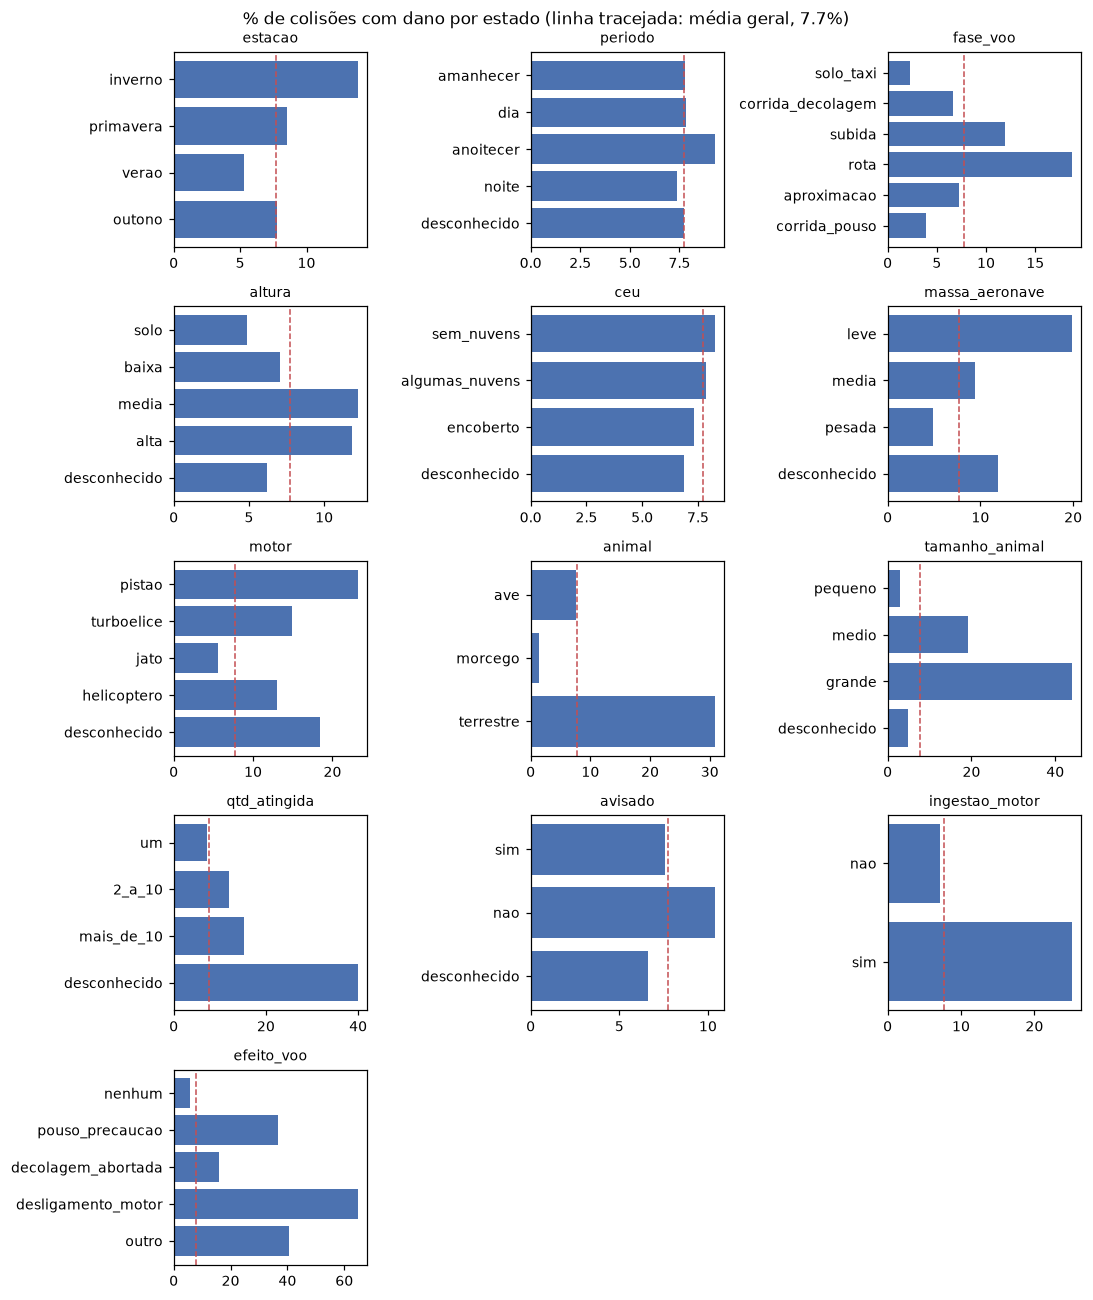

In [9]:
# Funil de registros (do relatório do script) e taxa de dano por estado de cada variável.
import re
funil = re.findall(r"- (.+?): ([\d,]+)", relatorio_coleta)
tab_funil = pd.DataFrame([(t, int(n.replace(",", ""))) for t, n in funil], columns=["Etapa", "Registros"])
tab_funil.loc[len(tab_funil)] = ["base final", len(df)]
salvar_tab(tab_funil, "tab_funil")
display(tab_funil)

taxa_base = (df["houve_dano"] == "sim").mean()
preditoras = [c for c in NOS if c != "houve_dano"]
fig, eixos = plt.subplots(5, 3, figsize=(10, 12))
for ax, c in zip(eixos.flat, preditoras):
    taxa = df.groupby(c, observed=False)["houve_dano"].apply(lambda s: 100 * (s == "sim").mean())
    ax.barh(taxa.index.astype(str), taxa.values, color="#4C72B0")
    ax.axvline(100 * taxa_base, color="#C44E52", ls="--", lw=1)
    ax.set_title(c, fontsize=9)
    ax.invert_yaxis()
for ax in eixos.flat[len(preditoras):]:
    ax.axis("off")
fig.suptitle(f"% de colisões com dano por estado (linha tracejada: média geral, {100 * taxa_base:.1f}%)")
fig.tight_layout()
salvar_fig(fig, "fig_taxa_dano_por_estado")
plt.show()

**Discussão.** Os maiores contrastes estão nas variáveis ligadas à energia do impacto e à fragilidade da aeronave.
Animal grande causa dano em 44,0% das colisões; animal pequeno, em 2,9%. Mamíferos terrestres (30,9%) superam de longe
aves (7,5%) e morcegos (1,4%). Do lado da aeronave, as leves sofrem dano em 19,9% das colisões e as pesadas em 4,9%, e o
motor a pistão (23,2%) fica bem acima do jato (5,6%). Ingestão pelo motor triplica a taxa (25,1% contra 7,2%), e colisões
em rota (18,7%) e em subida (11,9%) danificam mais do que as da corrida de pouso (3,9%), onde a velocidade é menor.

O contexto pesa menos. Período do dia e céu ficam todos entre 6,9% e 9,3%, perto da média de 7,7%. A exceção é a estação:
no inverno a taxa chega a 13,9%, contra 5,3% no verão. A rede aprendida não liga a estação diretamente ao dano;
se esse efeito existe, ele passa por outras variáveis.

Os estados `desconhecido` não são neutros. `qtd_atingida = desconhecido` tem 40% de dano (só 65 casos) e
`motor = desconhecido`, 18,4%. Relatos incompletos vêm de fontes e situações diferentes dos relatos completos, e a
rede vai tratar essa diferença como informação. Os tercis de altura mostram outra assimetria: a faixa `baixa` vai até
350 pés e a `alta` começa em 1.700, porque a distribuição das alturas positivas é muito concentrada perto do solo.

### Perguntas de interesse

A rede deve ser capaz de responder:

* **Q1 (preditiva)** — Dado o perfil de uma colisão (aeronave, motor, animal, fase do voo), qual a probabilidade de
  a aeronave sofrer dano?
* **Q2 (consequência operacional)** — Quando há ingestão de animal pelo motor, quão provável é um efeito no voo
  (pouso de precaução, decolagem abortada, desligamento do motor)?
* **Q3 (diagnóstica)** — Sabendo que o motor teve de ser desligado, o que provavelmente atingiu a aeronave
  (tamanho do animal, quantidade)?
* **Q4 (intervencional)** — Se o piloto fosse sempre avisado da presença de fauna, o risco de dano mudaria?

## 3. Tarefa 2 — Estrutura elicitada manualmente

Antes de qualquer aprendizado, desenhamos a rede que julgamos fazer sentido para o domínio (figura original em
`INPUTS/rede_etapa2.png`). A ideia geral: o **contexto** (estação, período, fase do voo, altura) determina que
animal se encontra; o **animal** (tamanho, quantidade) e a **aeronave** (massa, motor) determinam a ingestão pelo
motor e o dano; o dano e a ingestão determinam o **efeito no voo**.

| Aresta | Justificativa |
|---|---|
| Estação → Céu | O padrão de nebulosidade muda ao longo do ano. |
| Céu → Aviso | Com visibilidade ruim, avisos de fauna seriam mais frequentes ou mais difíceis de dar. |
| Estação → Animal | Migrações e hibernação mudam a fauna presente. |
| Período → Animal | Morcegos são noturnos; mamíferos terrestres aparecem mais ao amanhecer e anoitecer. |
| Fase do voo → Altura | A fase determina a altitude (corrida de pouso no solo, rota em altitude). |
| Altura → Animal | Mamíferos só são atingidos no solo; morcegos e aves em altitude. |
| Animal → Tamanho do animal | Mamíferos terrestres tendem a ser grandes; morcegos, pequenos. |
| Animal → Quantidade atingida | Aves voam em bandos; mamíferos costumam estar sozinhos. |
| Tamanho do animal → Houve dano | Maior massa, maior energia de impacto. |
| Quantidade atingida → Houve dano | Mais impactos, mais chance de dano. |
| Quantidade atingida → Ingestão motor | Um bando aumenta a chance de um animal entrar no motor. |
| Massa da aeronave → Motor | Aeronaves leves usam pistão; pesadas, jato. |
| Motor → Ingestão motor | Turbofans aspiram o ar à frente; hélices e rotores não. |
| Massa da aeronave → Houve dano | Aeronaves leves têm estrutura menos resistente. |
| Ingestão motor → Houve dano | A ingestão pode danificar o motor. |
| Ingestão motor → Efeito no voo | Ingestão leva a desligamento do motor ou pouso de precaução. |
| Houve dano → Efeito no voo | Dano leva a pouso de precaução ou decolagem abortada. |

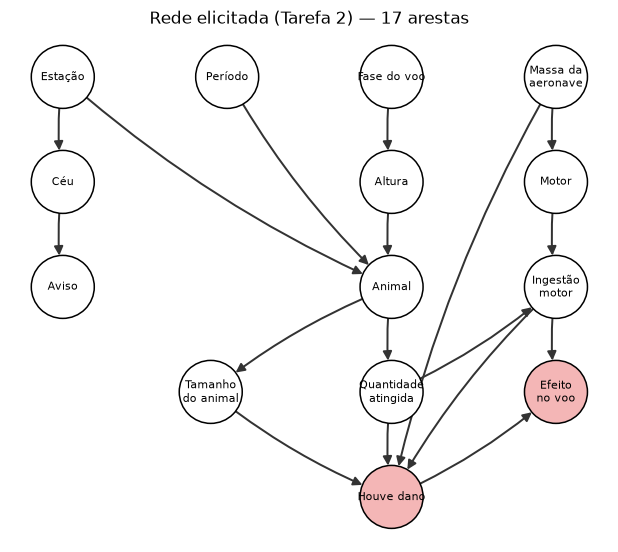

In [10]:
from pgmpy.base import DAG

ARESTAS_ELICITADAS = [
    ("estacao", "ceu"), ("ceu", "avisado"),
    ("estacao", "animal"), ("periodo", "animal"),
    ("fase_voo", "altura"), ("altura", "animal"),
    ("animal", "tamanho_animal"), ("animal", "qtd_atingida"),
    ("tamanho_animal", "houve_dano"), ("qtd_atingida", "houve_dano"),
    ("qtd_atingida", "ingestao_motor"),
    ("massa_aeronave", "motor"), ("motor", "ingestao_motor"),
    ("massa_aeronave", "houve_dano"),
    ("ingestao_motor", "houve_dano"), ("ingestao_motor", "efeito_voo"),
    ("houve_dano", "efeito_voo"),
]
dag_elic = DAG(ARESTAS_ELICITADAS)
dag_elic.add_nodes_from(NOS)
assert len(dag_elic.edges()) == 17 and nx.is_directed_acyclic_graph(dag_elic)

# Mesmo layout do desenho original, usado em todas as figuras de rede.
POS = {"estacao": (0, 5), "periodo": (2, 5), "fase_voo": (4, 5), "massa_aeronave": (6, 5),
       "ceu": (0, 4), "altura": (4, 4), "motor": (6, 4),
       "avisado": (0, 3), "animal": (4, 3), "ingestao_motor": (6, 3),
       "tamanho_animal": (1.8, 2), "qtd_atingida": (4, 2), "efeito_voo": (6, 2),
       "houve_dano": (4, 1)}
ALVOS = {"houve_dano", "efeito_voo"}

def desenhar(g, ax, titulo, cor_aresta=None, cor_no=None):
    cor_aresta = cor_aresta or {}
    cor_no = cor_no or {n: ("#F4B6B6" if n in ALVOS else "white") for n in g.nodes()}
    nx.draw_networkx_nodes(g, POS, ax=ax, node_size=1700, node_color=[cor_no[n] for n in g.nodes()],
                           edgecolors="black", linewidths=1)
    nx.draw_networkx_labels(g, POS, labels={n: ROTULOS[n] for n in g.nodes()}, font_size=7, ax=ax)
    # Arestas verticais longas atravessariam os nós do meio da coluna; elas ganham uma curva maior.
    def longa(e):
        (x1, y1), (x2, y2) = POS[e[0]], POS[e[1]]
        return abs(x1 - x2) < 0.5 and abs(y1 - y2) > 1
    for curva, arestas in ((0.08, [e for e in g.edges() if not longa(e)]), (0.35, [e for e in g.edges() if longa(e)])):
        nx.draw_networkx_edges(g, POS, edgelist=arestas, ax=ax, node_size=1700, arrows=True, arrowsize=12,
                               width=1.3, edge_color=[cor_aresta.get(e, "#333333") for e in arestas],
                               connectionstyle=f"arc3,rad={curva}")
    ax.set_title(titulo)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(7, 6))
desenhar(dag_elic, ax, "Rede elicitada (Tarefa 2) — 17 arestas")
salvar_fig(fig, "fig_rede_elicitada")
plt.show()

## 4. Tarefa 3 — Aprendizado de estrutura

### 4.1 Hill-Climbing com score BIC

O Hill-Climbing parte do grafo vazio e, a cada passo, aplica a operação local (inserir, remover ou inverter uma
aresta, mantendo o grafo acíclico) que mais aumenta o score; para quando nenhuma operação melhora o score — um
ótimo local. O score é o BIC,

$$\mathrm{BIC}(G) = \log P(D \mid \hat\theta_G) - \frac{k_G}{2}\log n,$$

a log-verossimilhança dos dados com os parâmetros de máxima verossimilhança menos uma penalidade proporcional ao
número $k_G$ de parâmetros livres. Usamos o Hill-Climbing puro (`tabu_length=0`, sem lista tabu).

Hill-Climbing: 29 arestas em 2.8 s; grau de entrada máximo 3; 1,182 parâmetros livres
Pais de cada nó:
  estacao         ← ['altura', 'periodo']
  periodo         ← ['altura', 'animal', 'ceu']
  fase_voo        ← ['ceu', 'motor']
  altura          ← ['avisado', 'ceu', 'fase_voo']
  ceu             ← ['avisado']
  massa_aeronave  ← ['avisado', 'ceu', 'houve_dano']
  motor           ← ['houve_dano', 'massa_aeronave']
  animal          ← ['altura', 'tamanho_animal']
  tamanho_animal  ← ['avisado', 'ceu']
  qtd_atingida    ← ['periodo', 'tamanho_animal']
  avisado         ← []
  ingestao_motor  ← ['houve_dano', 'massa_aeronave', 'qtd_atingida']
  houve_dano      ← ['tamanho_animal']
  efeito_voo      ← ['fase_voo', 'houve_dano', 'massa_aeronave']


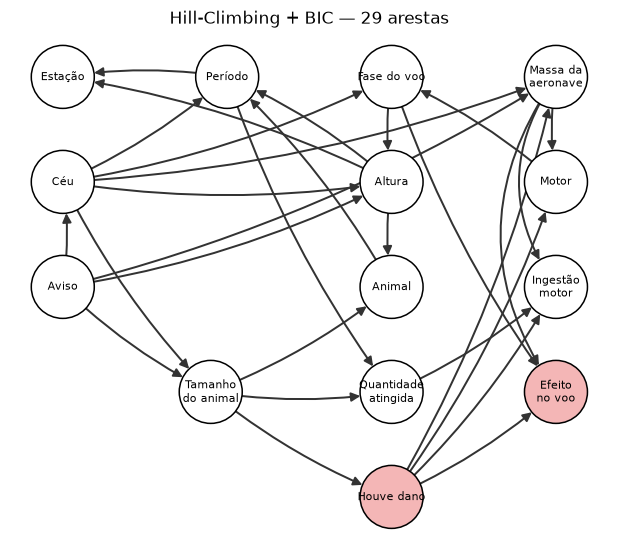

In [11]:
from pgmpy.causal_discovery import HillClimbSearch
from pgmpy.metrics import StructureScore

bic = StructureScore(scoring_method="bic-d")

def n_parametros(g):
    card = {c: len(STATE_NAMES[c]) for c in NOS}
    return sum((card[x] - 1) * int(np.prod([card[p] for p in g.predecessors(x)])) for x in g.nodes())

t0 = time.time()
hc = HillClimbSearch(scoring_method="bic-d", return_type="dag", tabu_length=0, show_progress=False).fit(dados)
dag_hc = hc.causal_graph_
dag_hc.add_nodes_from(NOS)
assert nx.is_directed_acyclic_graph(dag_hc)
print(f"Hill-Climbing: {len(dag_hc.edges())} arestas em {time.time() - t0:.1f} s; "
      f"grau de entrada máximo {max(d for _, d in dag_hc.in_degree())}; {n_parametros(dag_hc):,} parâmetros livres")
print("Pais de cada nó:")
for n in NOS:
    print(f"  {n:15s} ← {sorted(dag_hc.predecessors(n))}")

fig, ax = plt.subplots(figsize=(7, 6))
desenhar(dag_hc, ax, f"Hill-Climbing + BIC — {len(dag_hc.edges())} arestas")
salvar_fig(fig, "fig_rede_hc")
plt.show()

### 4.2 Chow-Liu

O algoritmo de Chow-Liu restringe a busca a **árvores**: calcula a informação mútua $I(X_i;X_j)$ entre todos os
pares de variáveis, encontra a árvore geradora de peso máximo e orienta as arestas a partir de uma raiz. O resultado
tem $n-1 = 13$ arestas e cada nó tem no máximo um pai. Como uma árvore orientada não tem v-estruturas, qualquer
escolha de raiz gera a mesma classe de equivalência de Markov e, portanto, o mesmo BIC; escolhemos a raiz que deixa
mais arestas com a mesma orientação da rede elicitada.

Chow-Liu: 10.1 s


Raiz escolhida: massa_aeronave (4 arestas com a orientação da elicitada); BIC idêntico para as 14 raízes: -712,940.9
Arestas: [('altura', 'ceu'), ('altura', 'estacao'), ('altura', 'periodo'), ('ceu', 'avisado'), ('ceu', 'tamanho_animal'), ('fase_voo', 'altura'), ('fase_voo', 'efeito_voo'), ('houve_dano', 'ingestao_motor'), ('massa_aeronave', 'motor'), ('motor', 'fase_voo'), ('tamanho_animal', 'animal'), ('tamanho_animal', 'houve_dano'), ('tamanho_animal', 'qtd_atingida')]


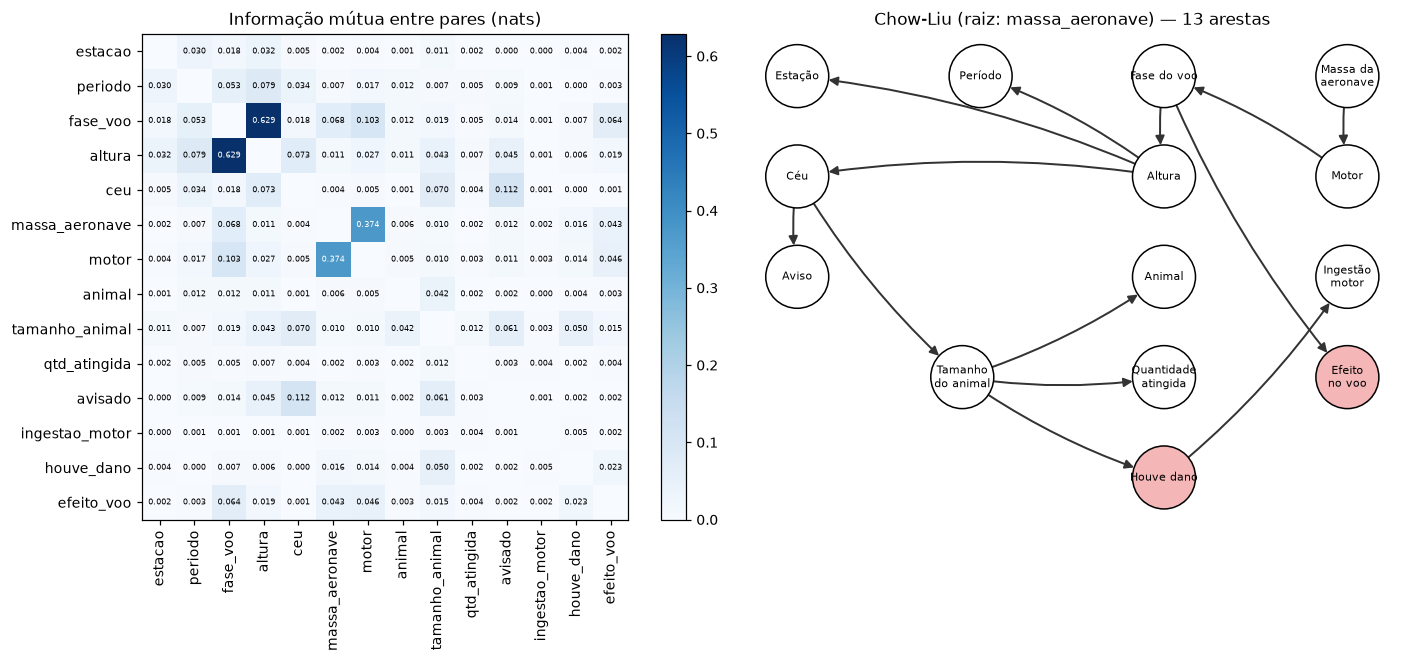

In [12]:
from pgmpy.estimators import TreeSearch

info_mutua = pd.DataFrame(0.0, index=NOS, columns=NOS)
for a, b in product(NOS, NOS):
    if a < b:
        info_mutua.loc[a, b] = info_mutua.loc[b, a] = mutual_info_score(dados[a], dados[b])

# O Chow-Liu é calculado uma vez: a árvore geradora máxima não depende da raiz. O pgmpy orienta a árvore com uma
# busca em largura a partir da raiz (nx.bfs_tree), e repetimos essa orientação para cada raiz candidata.
# n_jobs=1: o padrão (-1) abre um processo por núcleo e multiplica o uso de memória.
t0 = time.time()
arvore = TreeSearch(dados, root_node=NOS[0], n_jobs=1).estimate(estimator_type="chow-liu", show_progress=False)
arvore_nao_orientada = nx.Graph(arvore.edges())
print(f"Chow-Liu: {time.time() - t0:.1f} s")

def orientar(raiz):
    g = DAG(nx.bfs_tree(arvore_nao_orientada, raiz).edges())
    g.add_nodes_from(NOS)
    return g

assert set(orientar(NOS[0]).edges()) == set(arvore.edges())
arvores = {r: orientar(r) for r in NOS}
concordancia = {r: len(set(g.edges()) & set(ARESTAS_ELICITADAS)) for r, g in arvores.items()}
raiz = max(NOS, key=lambda r: concordancia[r])
dag_cl = arvores[raiz]
bics_raizes = {r: round(bic(X=dados, causal_graph=g), 3) for r, g in arvores.items()}
assert len(set(bics_raizes.values())) == 1, "raízes diferentes deveriam dar o mesmo BIC"
assert len(dag_cl.edges()) == 13 and max(d for _, d in dag_cl.in_degree()) <= 1
print(f"Raiz escolhida: {raiz} ({concordancia[raiz]} arestas com a orientação da elicitada); "
      f"BIC idêntico para as 14 raízes: {next(iter(bics_raizes.values())):,.1f}")
print("Arestas:", sorted(dag_cl.edges()))

fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1]})
im = axs[0].imshow(info_mutua.values, cmap="Blues")
axs[0].set_xticks(range(len(NOS)), NOS, rotation=90)
axs[0].set_yticks(range(len(NOS)), NOS)
for (i, j), v in np.ndenumerate(info_mutua.values):
    if i != j:
        axs[0].text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=5.5,
                    color="white" if v > info_mutua.values.max() / 2 else "black")
axs[0].set_title("Informação mútua entre pares (nats)")
fig.colorbar(im, ax=axs[0], fraction=0.046)
desenhar(dag_cl, axs[1], f"Chow-Liu (raiz: {raiz}) — 13 arestas")
fig.tight_layout()
salvar_fig(fig, "fig_rede_chowliu")
plt.show()

### 4.3 Comparação com a estrutura elicitada

O BIC é *score-equivalente*: dois DAGs com as mesmas independências condicionais (mesma classe de equivalência de
Markov) têm o mesmo score. Por isso a orientação de uma aresta só é evidência dos dados quando ela é **compelida**,
isto é, aparece orientada no CPDAG (o grafo que representa a classe). Comparamos então: (i) as arestas, como
desenhadas; (ii) os CPDAGs, com uma distância de Hamming estrutural (SHD) que conta os pares de variáveis cujo
estado — sem aresta, `→`, `←` ou não orientada — difere entre os dois grafos.

In [13]:
def estado_par(pdag, a, b):
    if (a, b) in pdag.directed_edges:
        return "→"
    if (b, a) in pdag.directed_edges:
        return "←"
    if (a, b) in pdag.undirected_edges or (b, a) in pdag.undirected_edges:
        return "—"
    return None

def shd_cpdag(g1, g2):
    p1, p2 = g1.to_pdag(), g2.to_pdag()
    return sum(estado_par(p1, a, b) != estado_par(p2, a, b) for i, a in enumerate(NOS) for b in NOS[i + 1:])

def situacao(aresta, g):
    a, b = aresta
    if g.has_edge(a, b):
        return "igual"
    if g.has_edge(b, a):
        reversivel = estado_par(g.to_pdag(), a, b) == "—"
        return "invertida (reversível)" if reversivel else "invertida (compelida)"
    return "ausente"

ESTRUTURAS = {"Elicitada": dag_elic, "Hill-Climbing + BIC": dag_hc, "Chow-Liu": dag_cl}
tab_metricas = pd.DataFrame([{
    "Estrutura": nome, "Arestas": len(g.edges()), "Parâmetros livres": n_parametros(g),
    "BIC": round(bic(X=dados, causal_graph=g), 1),
    "SHD (CPDAG) vs elicitada": shd_cpdag(dag_elic, g), "SHD (CPDAG) vs HC": shd_cpdag(dag_hc, g)}
    for nome, g in ESTRUTURAS.items()])
salvar_tab(tab_metricas, "tab_metricas_estruturas")
display(tab_metricas)

linhas = [{"Aresta elicitada": f"{a} → {b}", "Hill-Climbing": situacao((a, b), dag_hc),
           "Chow-Liu": situacao((a, b), dag_cl), "IM (nats)": round(info_mutua.loc[a, b], 4)}
          for a, b in ARESTAS_ELICITADAS]
tab_arestas = pd.DataFrame(linhas)
salvar_tab(tab_arestas, "tab_comparacao_arestas")
display(tab_arestas)

def so_aprendidas(g):
    return pd.DataFrame([{"Aresta": f"{a} → {b}", "No CPDAG": estado_par(g.to_pdag(), a, b),
                          "IM (nats)": round(info_mutua.loc[a, b], 4)}
                         for a, b in sorted(g.edges())
                         if not dag_elic.has_edge(a, b) and not dag_elic.has_edge(b, a)])
tab_so_hc, tab_so_cl = so_aprendidas(dag_hc), so_aprendidas(dag_cl)
salvar_tab(tab_so_hc, "tab_arestas_so_hc")
salvar_tab(tab_so_cl, "tab_arestas_so_cl")
print("Arestas só no Hill-Climbing:")
display(tab_so_hc)
print("Arestas só no Chow-Liu:")
display(tab_so_cl)

,Estrutura,Arestas,Parâmetros livres,BIC,SHD (CPDAG) vs elicitada,SHD (CPDAG) vs HC
0,Elicitada,17,457,-739939.7,0,31
1,Hill-Climbing + BIC,29,1182,-701077.0,31,0
2,Chow-Liu,13,188,-712940.9,21,26


,Aresta elicitada,Hill-Climbing,Chow-Liu,IM (nats)
0,estacao → ceu,ausente,ausente,0.0051
1,ceu → avisado,invertida (reversível),igual,0.1115
2,estacao → animal,ausente,ausente,0.0012
3,periodo → animal,invertida (compelida),ausente,0.0122
4,fase_voo → altura,igual,igual,0.6287
5,altura → animal,igual,ausente,0.0113
6,animal → tamanho_animal,invertida (compelida),invertida (reversível),0.0416
7,animal → qtd_atingida,ausente,ausente,0.0021
8,tamanho_animal → houve_dano,igual,igual,0.0502
9,qtd_atingida → houve_dano,ausente,ausente,0.0018


Arestas só no Hill-Climbing:


,Aresta,No CPDAG,IM (nats)
0,altura → estacao,→,0.0323
1,altura → periodo,→,0.0786
2,avisado → altura,→,0.0446
3,avisado → massa_aeronave,→,0.0120
4,avisado → tamanho_animal,—,0.0612
5,ceu → altura,→,0.0726
6,ceu → fase_voo,→,0.0184
7,ceu → massa_aeronave,→,0.0037
8,ceu → periodo,→,0.0337
9,ceu → tamanho_animal,—,0.0700


Arestas só no Chow-Liu:


,Aresta,No CPDAG,IM (nats)
0,altura → ceu,—,0.0726
1,altura → estacao,—,0.0323
2,altura → periodo,—,0.0786
3,ceu → tamanho_animal,—,0.0700
4,fase_voo → efeito_voo,—,0.0643
5,motor → fase_voo,—,0.1026
6,tamanho_animal → qtd_atingida,—,0.0120


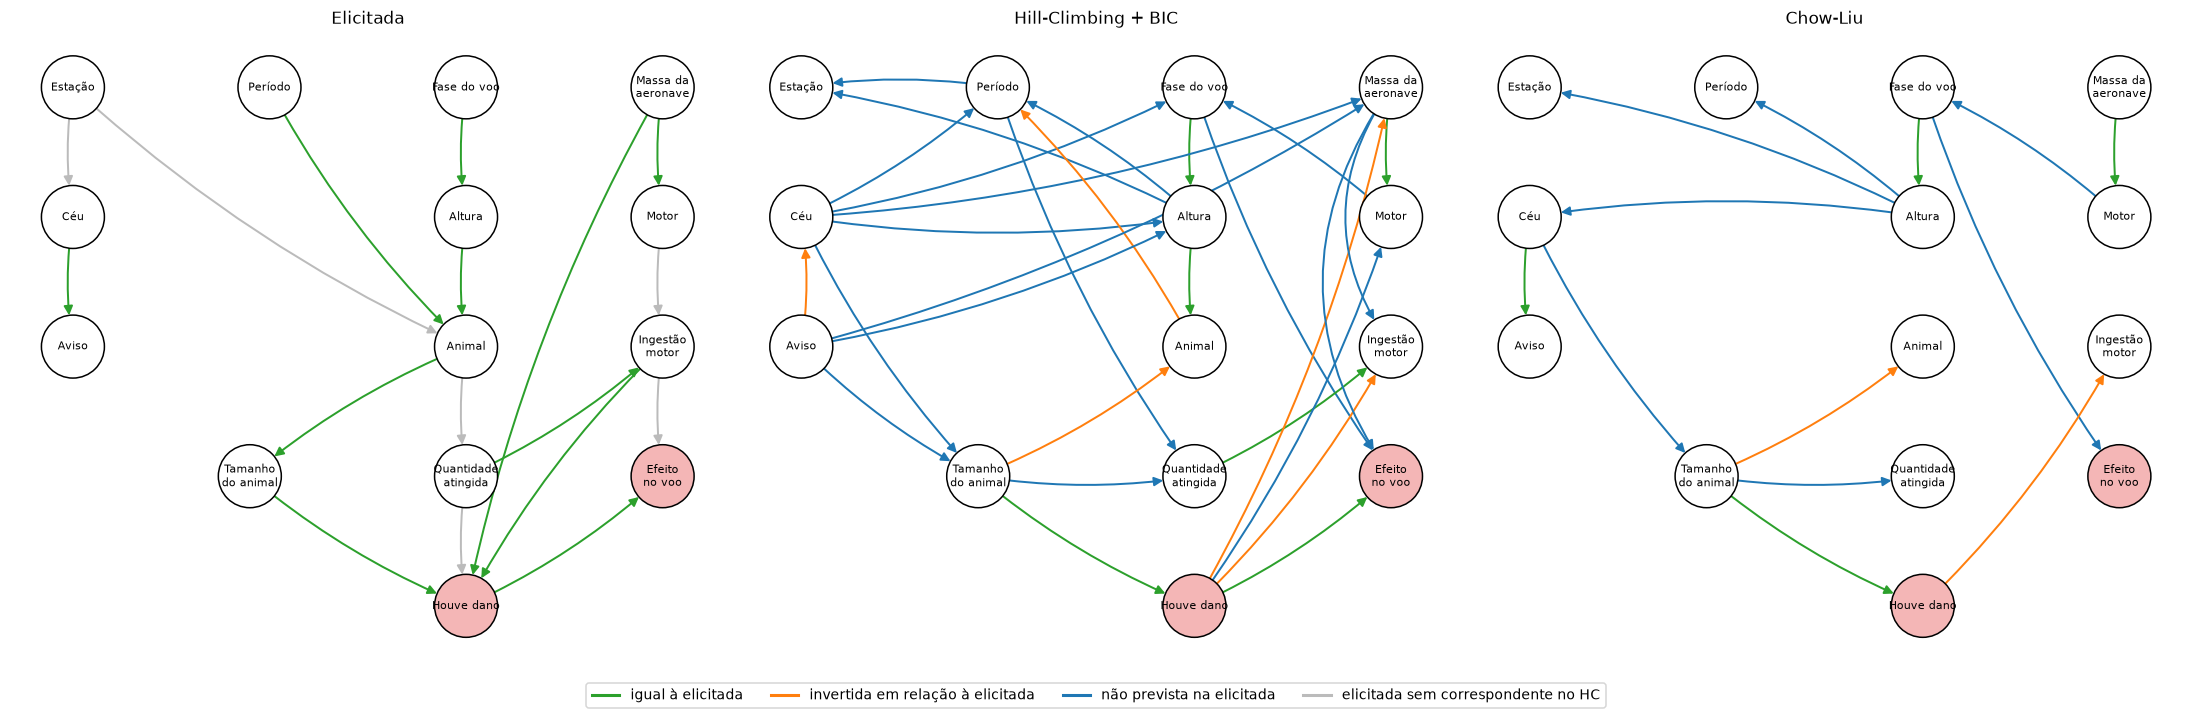

In [14]:
CORES = {"igual": "#2CA02C", "invertida": "#FF7F0E", "nova": "#1F77B4", "ausente": "#BBBBBB"}

def cores_comparacao(g):
    cores = {}
    for a, b in g.edges():
        if dag_elic.has_edge(a, b):
            cores[(a, b)] = CORES["igual"]
        elif dag_elic.has_edge(b, a):
            cores[(a, b)] = CORES["invertida"]
        else:
            cores[(a, b)] = CORES["nova"]
    return cores

fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
desenhar(dag_elic, axs[0], "Elicitada",
         {e: (CORES["igual"] if (dag_hc.has_edge(*e) or dag_hc.has_edge(*e[::-1])) else CORES["ausente"])
          for e in dag_elic.edges()})
desenhar(dag_hc, axs[1], "Hill-Climbing + BIC", cores_comparacao(dag_hc))
desenhar(dag_cl, axs[2], "Chow-Liu", cores_comparacao(dag_cl))
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], color=c, lw=2) for c in CORES.values()],
           ["igual à elicitada", "invertida em relação à elicitada", "não prevista na elicitada",
            "elicitada sem correspondente no HC"], loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.05, 1, 1))
salvar_fig(fig, "fig_comparacao")
plt.show()

In [15]:
# Os estados "desconhecido" aparecem juntos? Se sim, parte das dependências vem da forma do relato, não do fenômeno.
com_desc = [c for c in NOS if "desconhecido" in STATE_NAMES[c]]
desc = pd.DataFrame({c: (df[c] == "desconhecido") for c in com_desc})
coocorrencia = pd.DataFrame(
    [[desc.loc[desc[a], b].mean() / desc[b].mean() if a != b else np.nan for b in com_desc] for a in com_desc],
    index=com_desc, columns=com_desc).round(2)
print("Razão P(B desconhecido | A desconhecido) / P(B desconhecido)  (1 = independentes):")
display(coocorrencia)

Razão P(B desconhecido | A desconhecido) / P(B desconhecido)  (1 = independentes):


,periodo,altura,ceu,massa_aeronave,motor,tamanho_animal,qtd_atingida,avisado
periodo,NaN,1.43,2.49,1.64,1.66,1.42,3.53,1.32
altura,1.43,NaN,2.21,1.37,1.34,1.73,1.79,1.40
ceu,2.49,2.21,NaN,1.40,1.35,2.23,2.58,1.77
massa_aeronave,1.64,1.37,1.40,NaN,112.84,1.15,17.02,1.34
motor,1.66,1.34,1.35,112.84,NaN,1.03,8.02,1.27
tamanho_animal,1.42,1.73,2.23,1.15,1.03,NaN,0.95,1.58
qtd_atingida,3.53,1.79,2.58,17.02,8.02,0.95,NaN,1.46
avisado,1.32,1.40,1.77,1.34,1.27,1.58,1.46,NaN


**Discussão.** O Hill-Climbing chegou a 29 arestas e BIC de −701.077; a rede elicitada, com 17 arestas, fica em
−739.940, e a árvore de Chow-Liu, com só 13, em −712.941. Que uma árvore supere o desenho manual em quase 27 mil
pontos de BIC já diz que a intuição deixou de fora dependências fortes, e a matriz de informação mútua mostra quais:
`motor`–`fase_voo` (0,103), `altura`–`periodo` (0,079), `ceu`–`altura` (0,073), `ceu`–`tamanho_animal` (0,070) e
`fase_voo`–`efeito_voo` (0,064) são mais fortes que quase todas as arestas desenhadas. A árvore de Chow-Liu, aliás, está
inteira dentro do esqueleto do Hill-Climbing: as 13 ligações mais informativas formam a espinha da rede aprendida.

**Onde o algoritmo concordou.** Seis arestas elicitadas aparecem iguais no Hill-Climbing: `fase_voo → altura`,
`altura → animal`, `tamanho_animal → houve_dano`, `qtd_atingida → ingestao_motor`, `massa_aeronave → motor` e
`houve_dano → efeito_voo`. São justamente as relações físicas mais diretas do desenho. O Chow-Liu reproduz quatro delas
e mais duas com orientação trocada, o que numa árvore não tem significado (todas as orientações são equivalentes).

**Onde discordou.** Seis arestas elicitadas não aparecem em nenhuma das redes aprendidas, e todas têm informação mútua
baixíssima, entre 0,0012 e 0,0051 nats: `estacao → ceu`, `estacao → animal`, `animal → qtd_atingida`,
`qtd_atingida → houve_dano`, `motor → ingestao_motor` e `ingestao_motor → efeito_voo`. A penalidade do BIC é de
$\frac{1}{2}\log n \approx 5{,}6$ por parâmetro, e uma aresta que entra num nó com muitos pais multiplica o número de
parâmetros. O caso de `ingestao_motor → efeito_voo` é o mais instrutivo: acrescentá-la à rede aprendida aumenta a
log-verossimilhança em 154, mas custa 192 parâmetros novos, e o BIC cai 920. Como só 3% das colisões têm ingestão, o
efeito, grande em termos relativos, contribui pouco para a verossimilhança total. Essa ausência volta a aparecer na
Tarefa 4.

Cinco arestas aparecem invertidas no Hill-Climbing. Só `ceu → avisado` é reversível, isto é, os dados não distinguem as
duas orientações. As outras quatro (`periodo`–`animal`, `animal`–`tamanho_animal`, `massa_aeronave`–`houve_dano` e
`ingestao_motor`–`houve_dano`) são compeladas por v-estruturas. Nas duas últimas, a rede aprendida coloca `houve_dano`
como **pai** de `massa_aeronave` e de `ingestao_motor` (e, numa aresta que não estava no desenho, de `motor`). Causalmente isso não faz sentido (o dano não muda o peso da aeronave), mas
o BIC aprende uma fatoração da distribuição conjunta, não um mecanismo. As v-estruturas que fixam essas orientações,
como `avisado → massa_aeronave ← houve_dano` e `ceu → massa_aeronave`, dizem que as variáveis de origem são independentes
entre si e só se tornam dependentes quando se conhece a massa. Nada impede que isso seja um padrão da forma de relatar,
e não do fenômeno.

**Por que tantas arestas novas.** Das 18 arestas que só o Hill-Climbing encontrou, oito ligam entre si `avisado`, `ceu`,
`altura`, `periodo`, `estacao` e `tamanho_animal`, quatro delas variáveis com 22% a 51% de `desconhecido`. A tabela de coocorrência explica boa parte
disso: quando o céu é `desconhecido`, a chance de o período também ser é 2,5 vezes maior que a média, e a maioria dos pares
fica com razões entre 1,3 e 3,5. Relatos incompletos tendem a ser incompletos em vários campos
de uma vez, e, como o faltante virou um estado, a rede aprende essas dependências. Outras arestas novas são
legítimas e simplesmente não foram previstas: `motor → fase_voo` (helicópteros e aviões a pistão têm perfis de voo
diferentes dos jatos) e `fase_voo → efeito_voo` (uma decolagem abortada só pode acontecer durante a corrida de decolagem;
todos os 818 casos estão nessa fase).

## 5. Tarefa 4 — Estimação dos parâmetros e inferência

### 5.1 Máxima verossimilhança × estimação bayesiana

Com a estrutura do Hill-Climbing fixada, cada nó recebe uma tabela $P(X_i \mid \mathrm{Pa}(X_i))$.

* **Máxima verossimilhança (MLE):** $\hat\theta_{ijk} = N_{ijk}/N_{ij}$ — a frequência relativa de cada estado
  em cada configuração dos pais. Configurações raras dão estimativas instáveis, e combinações nunca vistas dão
  probabilidade zero.
* **Estimação bayesiana com prior BDeu:** soma pseudo-contagens uniformes,
  $\hat\theta_{ijk} = (N_{ijk} + \alpha/(q_i r_i)) / (N_{ij} + \alpha/q_i)$, onde $\alpha$ é o *tamanho amostral
  equivalente* (ESS), $r_i$ o número de estados do nó e $q_i$ o número de configurações dos pais.

Há estados raros na base (por exemplo `solo_taxi`, `desligamento_motor`, `qtd_atingida = desconhecido`). Para
escolher entre os estimadores, e o valor de $\alpha$, ajustamos cada um em 80% dos dados e medimos a
log-verossimilhança média nos 20% restantes.

In [16]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE

def ajustar(g, base, estimador):
    m = DiscreteBayesianNetwork(g.edges())
    m.add_nodes_from(NOS)
    m.fit(base, estimator=estimador)
    assert m.check_model()
    return m

def log_verossimilhanca(m, base):
    total = np.zeros(len(base))
    for cpd in m.get_cpds():
        indices = tuple(base[v].astype(str).map({s: i for i, s in enumerate(cpd.state_names[v])}).to_numpy()
                        for v in cpd.variables)
        with np.errstate(divide="ignore"):
            total += np.log(cpd.values[indices])
    return total

treino = dados.sample(frac=0.8, random_state=SEED)
teste = dados.drop(treino.index)
CANDIDATOS = {"MLE": lambda: DiscreteMLE(state_names=STATE_NAMES)}
for alfa in (1, 5, 10, 50, 100):
    CANDIDATOS[f"BDeu, α = {alfa}"] = lambda alfa=alfa: DiscreteBayesianEstimator(
        state_names=STATE_NAMES, prior_type="BDeu", equivalent_sample_size=alfa)

resultados = []
for nome, fabrica in CANDIDATOS.items():
    ll = log_verossimilhanca(ajustar(dag_hc, treino, fabrica()), teste)
    finitos = np.isfinite(ll)
    resultados.append({"Estimador": nome, "Registros com P = 0": int((~finitos).sum()),
                       "LL média no teste": round(ll.mean(), 4) if finitos.all() else -np.inf,
                       "LL média (só P > 0)": round(ll[finitos].mean(), 4)})
tab_estimadores = pd.DataFrame(resultados)
salvar_tab(tab_estimadores, "tab_estimadores")
display(tab_estimadores)
melhor = tab_estimadores.loc[tab_estimadores["LL média no teste"].idxmax(), "Estimador"]
print("Escolhido:", melhor)

,Estimador,Registros com P = 0,LL média no teste,LL média (só P > 0)
0,MLE,16,-inf,-9.5545
1,"BDeu, α = 1",0,-9.5691,-9.5691
2,"BDeu, α = 5",0,-9.5675,-9.5675
3,"BDeu, α = 10",0,-9.5669,-9.5669
4,"BDeu, α = 50",0,-9.5665,-9.5665
5,"BDeu, α = 100",0,-9.5675,-9.5675


Escolhido: BDeu, α = 50


In [17]:
modelo = ajustar(dag_hc, dados, CANDIDATOS[melhor]())
print("Modelo válido:", modelo.check_model(), "| CPDs:", len(modelo.get_cpds()))
for no in ("houve_dano", "efeito_voo"):
    cpd = modelo.get_cpds(no)
    print(f"\nP({no} | {', '.join(cpd.variables[1:]) or '—'})  —  {cpd.values.size} entradas")

def cpd_como_tabela(no):
    # Uma linha por configuração dos pais, uma coluna por estado do nó (em %).
    cpd = modelo.get_cpds(no)
    pais = cpd.variables[1:]
    valores = cpd.values.reshape(len(cpd.state_names[no]), -1).T
    configuracoes = list(product(*[cpd.state_names[p] for p in pais])) or [()]
    tabela = pd.DataFrame(100 * valores, columns=[f"{no}={e} (%)" for e in cpd.state_names[no]]).round(2)
    for k, p in enumerate(pais):
        tabela.insert(k, p, [c[k] for c in configuracoes])
    return tabela

tab_cpd_dano = cpd_como_tabela("houve_dano")
salvar_tab(tab_cpd_dano, "tab_cpd_houve_dano")
display(tab_cpd_dano)
tab_cpd_efeito = cpd_como_tabela("efeito_voo")
print("P(efeito_voo | pais) — configurações com houve_dano = sim:")
display(tab_cpd_efeito[tab_cpd_efeito["houve_dano"] == "sim"])

Modelo válido: True | CPDs: 14

P(houve_dano | tamanho_animal)  —  8 entradas

P(efeito_voo | fase_voo, houve_dano, massa_aeronave)  —  240 entradas


,tamanho_animal,houve_dano=nao (%),houve_dano=sim (%)
0,pequeno,97.06,2.94
1,medio,80.84,19.16
2,grande,55.97,44.03
3,desconhecido,95.13,4.87


P(efeito_voo | pais) — configurações com houve_dano = sim:


,fase_voo,houve_dano,massa_aeronave,efeito_voo=nenhum (%),efeito_voo=pouso_precaucao (%),efeito_voo=decolagem_abortada (%),efeito_voo=desligamento_motor (%),efeito_voo=outro (%)
4,solo_taxi,sim,leve,45.56,2.96,2.96,17.16,31.36
5,solo_taxi,sim,media,20.00,20.00,20.00,20.00,20.00
6,solo_taxi,sim,pesada,59.18,10.20,10.20,10.20,10.20
7,solo_taxi,sim,desconhecido,20.00,20.00,20.00,20.00,20.00
12,corrida_decolagem,sim,leve,25.14,18.89,52.21,1.53,2.23
13,corrida_decolagem,sim,media,44.99,34.47,17.37,1.59,1.59
14,corrida_decolagem,sim,pesada,54.03,29.03,12.27,1.76,2.90
15,corrida_decolagem,sim,desconhecido,54.64,29.90,5.15,5.15,5.15
20,subida,sim,leve,39.37,57.33,0.05,1.02,2.23
21,subida,sim,media,48.74,48.74,0.11,1.75,0.66


### 5.2 Inferência: respostas às perguntas da Tarefa 1

As consultas usam eliminação de variáveis (inferência exata). Cada resposta é comparada com a frequência observada
nos registros que satisfazem a mesma evidência (coluna *Empírico*, com o número de registros de suporte). Onde há
muitos registros as duas devem coincidir; onde há poucos, a rede combina informação de configurações vizinhas.

,Perfil,Evidência,Rede (%),Empírico (%),Suporte
0,sem evidência,(nenhuma),7.8,7.7,72877
1,animal grande,tamanho_animal=grande,44.0,44.0,4301
2,"leve, pistão, animal terrestre","massa_aeronave=leve, motor=pistao, animal=terr...",71.4,69.0,252
3,"pesada, jato, ave pequena, aproximação","massa_aeronave=pesada, motor=jato, animal=ave,...",1.9,2.1,15548
4,"leve, pistão, animal grande, em rota","massa_aeronave=leve, motor=pistao, tamanho_ani...",73.2,81.7,115


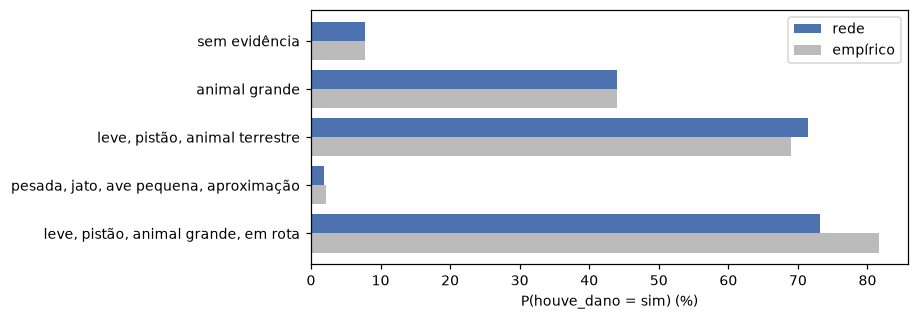

In [18]:
from pgmpy.inference import CausalInference, VariableElimination

inferencia = VariableElimination(modelo)
causal = CausalInference(modelo)

def consultar(alvo, estado, evidencia):
    p = inferencia.query([alvo], evidence=evidencia, show_progress=False).get_value(**{alvo: estado})
    mascara = np.ones(len(df), dtype=bool)
    for v, s in evidencia.items():
        mascara &= (df[v] == s).to_numpy()
    n = int(mascara.sum())
    empirico = (df.loc[mascara, alvo] == estado).mean() if n else np.nan
    return {"Evidência": ", ".join(f"{v}={s}" for v, s in evidencia.items()) or "(nenhuma)",
            "Rede (%)": round(100 * p, 1), "Empírico (%)": round(100 * empirico, 1), "Suporte": n}

PERFIS_Q1 = {
    "sem evidência": {},
    "animal grande": {"tamanho_animal": "grande"},
    "leve, pistão, animal terrestre": {"massa_aeronave": "leve", "motor": "pistao", "animal": "terrestre"},
    "pesada, jato, ave pequena, aproximação": {"massa_aeronave": "pesada", "motor": "jato", "animal": "ave",
                                               "tamanho_animal": "pequeno", "fase_voo": "aproximacao"},
    "leve, pistão, animal grande, em rota": {"massa_aeronave": "leve", "motor": "pistao",
                                             "tamanho_animal": "grande", "fase_voo": "rota"},
}
tab_q1 = pd.DataFrame([{"Perfil": nome, **consultar("houve_dano", "sim", ev)} for nome, ev in PERFIS_Q1.items()])
salvar_tab(tab_q1, "tab_q1")
display(tab_q1)

fig, ax = plt.subplots(figsize=(7, 3))
y = np.arange(len(tab_q1))
ax.barh(y - 0.2, tab_q1["Rede (%)"], 0.4, label="rede", color="#4C72B0")
ax.barh(y + 0.2, tab_q1["Empírico (%)"], 0.4, label="empírico", color="#BBBBBB")
ax.set_yticks(y, tab_q1["Perfil"]); ax.invert_yaxis()
ax.set_xlabel("P(houve_dano = sim) (%)"); ax.legend()
salvar_fig(fig, "fig_q1")
plt.show()

In [19]:
# Q2 — efeito no voo dado ingestão pelo motor
def distribuicao(alvo, evidencia, do=None):
    # Intervenção por "cirurgia" do grafo: modelo.do() remove as arestas que entram nas variáveis intervindas,
    # e P(alvo | do(X=x), e) = P_mutilado(alvo | X=x, e).
    if do:
        f = VariableElimination(modelo.do(list(do))).query([alvo], evidence={**evidencia, **do}, show_progress=False)
    else:
        f = inferencia.query([alvo], evidence=evidencia, show_progress=False)
    return pd.Series({s: f.get_value(**{alvo: s}) for s in STATE_NAMES[alvo]})

CENARIOS_Q2 = {"sem ingestão": {"ingestao_motor": "nao"}, "com ingestão": {"ingestao_motor": "sim"},
               "com ingestão, 2 a 10 animais": {"ingestao_motor": "sim", "qtd_atingida": "2_a_10"}}
linhas = []
for nome, ev in CENARIOS_Q2.items():
    rede = distribuicao("efeito_voo", ev)
    mascara = np.logical_and.reduce([(df[v] == s).to_numpy() for v, s in ev.items()])
    emp = df.loc[mascara, "efeito_voo"].value_counts(normalize=True).reindex(STATE_NAMES["efeito_voo"]).fillna(0)
    linhas.append({"Cenário": nome, "Suporte": int(mascara.sum()),
                   **{f"{s} (%)": f"{100 * rede[s]:.1f} ({100 * emp[s]:.1f})".replace(".", ",") for s in STATE_NAMES["efeito_voo"]}})
tab_q2 = pd.DataFrame(linhas)
salvar_tab(tab_q2, "tab_q2")
print("P(efeito_voo | evidência) — rede (empírico)")
display(tab_q2)

P(efeito_voo | evidência) — rede (empírico)


,Cenário,Suporte,nenhum (%),pouso_precaucao (%),decolagem_abortada (%),desligamento_motor (%),outro (%)
0,sem ingestão,70637,"93,5 (93,6)","4,5 (4,6)","1,2 (1,1)","0,2 (0,1)","0,7 (0,6)"
1,com ingestão,2240,"93,7 (84,9)","4,2 (10,8)","0,9 (2,0)","0,3 (1,2)","0,8 (1,1)"
2,"com ingestão, 2 a 10 animais",533,"93,9 (82,4)","4,1 (13,5)","1,0 (2,3)","0,3 (0,9)","0,8 (0,9)"


In [20]:
# Q3 — diagnóstico: o que atingiu a aeronave quando o motor foi desligado?
linhas = []
for alvo in ("tamanho_animal", "qtd_atingida"):
    for cond in ("nenhum", "desligamento_motor"):
        rede = distribuicao(alvo, {"efeito_voo": cond})
        emp = df.loc[df["efeito_voo"] == cond, alvo].value_counts(normalize=True).reindex(STATE_NAMES[alvo]).fillna(0)
        for s in STATE_NAMES[alvo]:
            linhas.append({"Variável": alvo, "Estado": s, "efeito_voo": cond,
                           "Rede (%)": round(100 * rede[s], 1), "Empírico (%)": round(100 * emp[s], 1)})
tab_q3 = (pd.DataFrame(linhas).pivot_table(index=["Variável", "Estado"], columns="efeito_voo",
                                           values=["Rede (%)", "Empírico (%)"], sort=False))
tab_q3.columns = [f"{m} | {e}" for m, e in tab_q3.columns]
tab_q3 = tab_q3.reset_index()
salvar_tab(tab_q3, "tab_q3")
print(f"Suporte: efeito_voo=desligamento_motor em {int((df['efeito_voo'] == 'desligamento_motor').sum())} registros")
display(tab_q3)

Suporte: efeito_voo=desligamento_motor em 111 registros


,Variável,Estado,Rede (%) | nenhum,Rede (%) | desligamento_motor,Empírico (%) | nenhum,Empírico (%) | desligamento_motor
0,tamanho_animal,pequeno,58.8,34.6,59.5,29.7
1,tamanho_animal,medio,11.5,22.5,11.1,27.0
2,tamanho_animal,grande,5.4,23.1,4.9,38.7
3,tamanho_animal,desconhecido,24.2,19.7,24.6,4.5
4,qtd_atingida,desconhecido,0.1,0.3,0.0,0.9
5,qtd_atingida,um,89.2,88.5,89.5,80.2
6,qtd_atingida,2_a_10,10.3,10.8,10.0,17.1
7,qtd_atingida,mais_de_10,0.5,0.4,0.4,1.8


In [21]:
# Q4 — intervenção: e se o piloto fosse sempre avisado?
linhas = [{"Consulta": "P(dano)", "P(dano = sim) (%)": round(100 * distribuicao("houve_dano", {})["sim"], 2)}]
for s in ("sim", "nao"):
    linhas.append({"Consulta": f"P(dano | avisado={s})",
                   "P(dano = sim) (%)": round(100 * distribuicao("houve_dano", {"avisado": s})["sim"], 2)})
    linhas.append({"Consulta": f"P(dano | do(avisado={s}))",
                   "P(dano = sim) (%)": round(100 * distribuicao("houve_dano", {}, do={"avisado": s})["sim"], 2)})
# Conferência com o módulo de inferência causal do pgmpy (aceita esta consulta porque houve_dano descende de avisado).
for s in ("sim", "nao"):
    f = causal.query(["houve_dano"], do={"avisado": s}, show_progress=False)
    assert abs(f.get_value(houve_dano="sim") - distribuicao("houve_dano", {}, do={"avisado": s})["sim"]) < 1e-9
tab_q4 = pd.DataFrame(linhas)
salvar_tab(tab_q4, "tab_q4")
print("Caminhos dirigidos de 'avisado' até 'houve_dano':", list(nx.all_simple_paths(modelo, "avisado", "houve_dano")))
display(tab_q4)

Caminhos dirigidos de 'avisado' até 'houve_dano': [['avisado', 'ceu', 'tamanho_animal', 'houve_dano'], ['avisado', 'tamanho_animal', 'houve_dano']]


,Consulta,P(dano = sim) (%)
0,P(dano),7.76
1,P(dano | avisado=sim),7.95
2,P(dano | do(avisado=sim)),7.95
3,P(dano | avisado=nao),9.28
4,P(dano | do(avisado=nao)),9.28


**Discussão.** A estimação por máxima verossimilhança atribuiu probabilidade zero a 16 colisões do conjunto de teste,
combinações de pais nunca vistas no treino, o que torna a log-verossimilhança $-\infty$. Com o prior BDeu nenhum
registro fica com probabilidade zero. Entre os valores de $\alpha$ as diferenças são pequenas (de −9,5691 a −9,5665
por registro), porque com 58 mil registros de treino o prior só pesa nas configurações raras; ficamos com $\alpha = 50$.

Na rede aprendida, `houve_dano` tem um único pai, `tamanho_animal`, e outros quatro nós como filhos. Por isso as
consultas sobre dano combinam raciocínio causal (pelo tamanho do animal) e diagnóstico (pelo que se observa nos filhos,
via regra de Bayes).

**Q1.** Onde há muitos registros, a rede reproduz os dados: 44,0% de dano para animal grande (4.301 casos) e 1,9% contra
2,1% para jato pesado atingindo ave pequena na aproximação (15.548 casos). Para aeronave leve a pistão atingindo animal
terrestre, a rede dá 71,4% e os 252 registros, 69,0%. A maior diferença está no perfil com só 115 registros (leve, pistão,
animal grande, em rota): 73,2% contra 81,7%. Com pouco suporte, a rede combina a evidência com o que aprendeu de
configurações parecidas, o que suaviza a estimativa.

**Q2.** Aqui a rede falha. Nos dados, a ingestão pelo motor faz a chance de algum efeito no voo subir de 6,4% para 15,1%,
com pouso de precaução em 10,8% dos casos. A rede praticamente não muda: 6,3% de efeito com ingestão, contra 6,5% sem.
Sem a aresta `ingestao_motor → efeito_voo`, a ingestão só alcança o efeito no voo por dois caminhos que se anulam. Pelo
dano, a ingestão aumenta a chance de efeito (a rede acerta P(dano | ingestão) em 24,4%, contra 25,1% nos dados). Pela
massa, a ingestão indica jato pesado (88% dos casos), e jatos pesados raramente registram efeito no voo. O efeito direto
da ingestão (motor afetado leva a pouso de precaução mesmo sem dano estrutural) se perdeu quando o BIC descartou a
aresta, como vimos na Tarefa 3. A rede elicitada tinha essa aresta; neste ponto, a intuição estava certa e o score não.

**Q3.** Quando o motor é desligado, a rede desloca a probabilidade na direção certa: animal grande passa de 5,4% para
23,1%. Mas os 111 registros mostram 38,7%, e a rede mantém 19,7% de tamanho `desconhecido` contra 4,5% observados. Com
a quantidade atingida acontece algo parecido (2 a 10 animais: 10,8% na rede, 17,1% nos dados). O efeito no voo só se
liga ao animal através de `houve_dano`, então a rede só consegue raciocinar "desligamento → houve dano → animal
grande", o que dilui a informação.

**Q4.** Como `avisado` é raiz da rede aprendida, não há caminho pela porta dos fundos, e intervir equivale a observar:
P(dano | do(avisado = sim)) = 7,95% e P(dano | do(avisado = não)) = 9,28%. O módulo `CausalInference` do pgmpy dá o mesmo
resultado. A leitura causal ("avisar o piloto reduz o dano em 1,3 ponto") seria precipitada. O efeito passa por
`avisado → tamanho_animal → houve_dano`, e um aviso não muda o tamanho do animal. O mais provável é que relatos que
registram o aviso também registrem melhor o tamanho. Uma intervenção só é tão causal quanto o grafo em que é calculada,
e este grafo foi aprendido para ajustar a distribuição, não para representar mecanismos.

## 6. Tarefa 5 — Explicando uma predição

Escolhemos um registro real com dano: entre as colisões com dano, ingestão pelo motor, em subida ou em rota e sem
nenhuma variável `desconhecido`, a de maior probabilidade de dano prevista pela rede. A evidência é tudo o que se sabe
sobre a colisão **exceto** o desfecho (`houve_dano`) e sua consequência (`efeito_voo`).

In [22]:
EVIDENCIAS = [c for c in NOS if c not in ("houve_dano", "efeito_voo")]
candidatos = df[(df["houve_dano"] == "sim") & (df["ingestao_motor"] == "sim")
                & df["fase_voo"].isin(["subida", "rota"])
                & (df[EVIDENCIAS] != "desconhecido").all(axis=1)]
combinacoes = candidatos.groupby(EVIDENCIAS, observed=True).size().reset_index(name="n")

def p_dano(evidencia, do=None):
    return distribuicao("houve_dano", evidencia, do=do)["sim"]

combinacoes["p_dano"] = [p_dano({c: str(r[c]) for c in EVIDENCIAS}) for _, r in combinacoes.iterrows()]
escolha = combinacoes.sort_values(["p_dano", "n"], ascending=False).iloc[0]
caso = {c: str(escolha[c]) for c in EVIDENCIAS}
registro = candidatos[(candidatos[EVIDENCIAS].astype(str) == pd.Series(caso)).all(axis=1)].iloc[0]
p_caso = p_dano(caso)
print(f"{len(candidatos)} colisões candidatas, {len(combinacoes)} combinações de evidência distintas")
print(f"Registro FAA {registro['id']} (ano {registro['ano']}): P(houve_dano = sim | evidência) = {100 * p_caso:.1f}% "
      f"(média da base: {100 * taxa_base:.1f}%)")
pd.Series(caso, name="evidência").to_frame()

70 colisões candidatas, 62 combinações de evidência distintas
Registro FAA 1515245 (ano 2024): P(houve_dano = sim | evidência) = 90.9% (média da base: 7.7%)


,evidência
estacao,inverno
periodo,dia
fase_voo,subida
altura,media
ceu,sem_nuvens
massa_aeronave,media
motor,jato
animal,ave
tamanho_animal,grande
qtd_atingida,um


### 6.1 Markov blanket

O *Markov blanket* de um nó (pais, filhos e outros pais dos filhos) o separa do resto da rede: dado o blanket, as
demais variáveis não alteram sua distribuição. Logo, a predição depende só das evidências que estão no blanket de
`houve_dano`.

In [23]:
blanket = [n for n in NOS if n in set(modelo.get_markov_blanket("houve_dano"))]  # ordem fixa
p_blanket = p_dano({c: caso[c] for c in blanket if c in caso})
print("Markov blanket de houve_dano:", blanket)
print(f"P(dano | toda a evidência) = {p_caso:.10f}\nP(dano | só o blanket)     = {p_blanket:.10f}")
assert abs(p_caso - p_blanket) < 1e-9

Markov blanket de houve_dano: ['fase_voo', 'ceu', 'massa_aeronave', 'motor', 'tamanho_animal', 'qtd_atingida', 'avisado', 'ingestao_motor', 'efeito_voo']
P(dano | toda a evidência) = 0.9086210226
P(dano | só o blanket)     = 0.9086210226


### 6.2 Análise de sensibilidade

Primeiro, retiramos uma evidência por vez e medimos quanto a probabilidade muda (Δ = P com tudo − P sem aquela
variável). Depois, para as variáveis mais influentes, variamos o estado mantendo o resto da evidência.

,Variável,Estado no caso,P sem ela (%),Δ (p.p.)
8,tamanho_animal,grande,53.59,37.27
11,ingestao_motor,sim,55.32,35.54
5,massa_aeronave,media,78.83,12.03
10,avisado,sim,89.49,1.37
4,ceu,sem_nuvens,89.50,1.36
9,qtd_atingida,um,90.54,0.32
6,motor,jato,91.11,-0.25
0,estacao,inverno,90.86,0.00
3,altura,media,90.86,0.00
2,fase_voo,subida,90.86,0.00


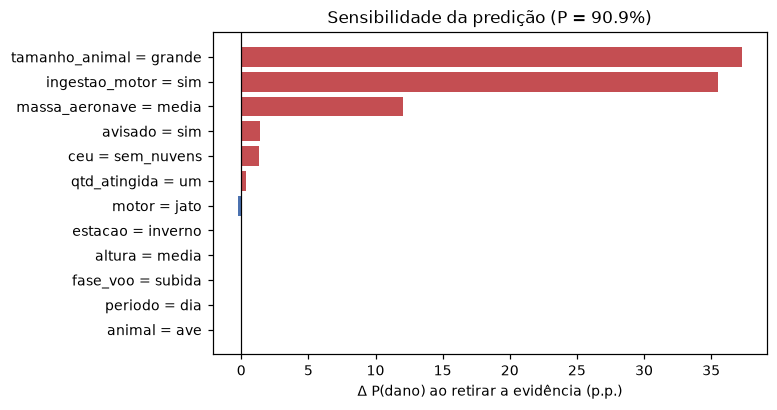

,Variável,Estado,P(dano) (%)
0,tamanho_animal,pequeno,27.7
1,tamanho_animal,medio,75.0
2,tamanho_animal,grande (caso),90.9
3,tamanho_animal,desconhecido,39.3
4,ingestao_motor,nao,53.3
5,ingestao_motor,sim (caso),90.9
6,massa_aeronave,leve,77.3
7,massa_aeronave,media (caso),90.9
8,massa_aeronave,pesada,77.8
9,massa_aeronave,desconhecido,84.0


In [24]:
sensibilidade = pd.DataFrame([{"Variável": c, "Estado no caso": caso[c],
                               "P sem ela (%)": 100 * p_dano({k: v for k, v in caso.items() if k != c}),
                               } for c in EVIDENCIAS])
sensibilidade["Δ (p.p.)"] = 100 * p_caso - sensibilidade["P sem ela (%)"]
sensibilidade = sensibilidade.reindex(sensibilidade["Δ (p.p.)"].abs().sort_values(ascending=False).index)
sensibilidade = sensibilidade.round(2)
salvar_tab(sensibilidade, "tab_sensibilidade")
display(sensibilidade)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
cores = ["#C44E52" if d > 0 else "#4C72B0" for d in sensibilidade["Δ (p.p.)"]]
ax.barh(sensibilidade["Variável"] + " = " + sensibilidade["Estado no caso"], sensibilidade["Δ (p.p.)"], color=cores)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Δ P(dano) ao retirar a evidência (p.p.)")
ax.set_title(f"Sensibilidade da predição (P = {100 * p_caso:.1f}%)")
salvar_fig(fig, "fig_tornado")
plt.show()

influentes = sensibilidade["Variável"].head(3).tolist()
linhas = []
for c in influentes:
    for s in STATE_NAMES[c]:
        linhas.append({"Variável": c, "Estado": s + (" (caso)" if s == caso[c] else ""),
                       "P(dano) (%)": round(100 * p_dano({**caso, c: s}), 1)})
tab_estados = pd.DataFrame(linhas)
salvar_tab(tab_estados, "tab_sensibilidade_estados")
display(tab_estados)

### 6.3 Caminhos de influência

Uma evidência só influencia o alvo se existir um caminho ativo (d-conectado) entre elas. A tabela mostra, para cada
evidência, se ela está d-conectada a `houve_dano` sem outras evidências e dado o resto da evidência, e o caminho
mais curto no grafo.

,Evidência,d-conectada (sem evidência),d-conectada (dado o resto),Caminho mais curto
0,estacao,True,False,estacao ← periodo; periodo → qtd_atingida; qtd...
1,periodo,True,False,periodo → qtd_atingida; qtd_atingida → ingesta...
2,fase_voo,True,False,fase_voo → efeito_voo; efeito_voo ← houve_dano
3,altura,True,False,altura ← ceu; ceu → tamanho_animal; tamanho_an...
4,ceu,True,True,ceu → tamanho_animal; tamanho_animal → houve_dano
5,massa_aeronave,True,True,massa_aeronave ← houve_dano
6,motor,True,True,motor ← houve_dano
7,animal,True,False,animal ← tamanho_animal; tamanho_animal → houv...
8,tamanho_animal,True,True,tamanho_animal → houve_dano
9,qtd_atingida,True,True,qtd_atingida ← tamanho_animal; tamanho_animal ...


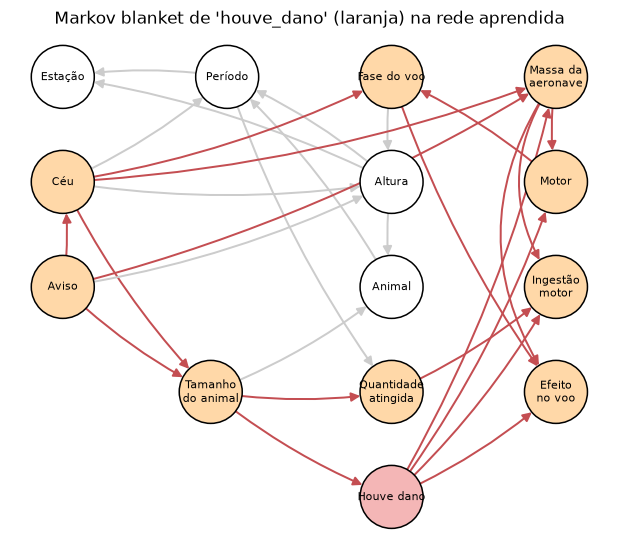

In [25]:
esqueleto = modelo.to_undirected()
linhas = []
for c in EVIDENCIAS:
    resto = [k for k in EVIDENCIAS if k != c]
    caminho = nx.shortest_path(esqueleto, c, "houve_dano")
    trechos = [f"{a} → {b}" if modelo.has_edge(a, b) else f"{a} ← {b}" for a, b in zip(caminho, caminho[1:])]
    linhas.append({"Evidência": c, "d-conectada (sem evidência)": modelo.is_dconnected(c, "houve_dano"),
                   "d-conectada (dado o resto)": modelo.is_dconnected(c, "houve_dano", observed=resto),
                   "Caminho mais curto": "; ".join(trechos)})
tab_caminhos = pd.DataFrame(linhas)
salvar_tab(tab_caminhos, "tab_caminhos", column_format="lccp{6.4cm}")
display(tab_caminhos)

cor_no = {n: ("#F4B6B6" if n == "houve_dano" else "#FFD8A8" if n in blanket else "white") for n in NOS}
cor_aresta = {(a, b): ("#C44E52" if "houve_dano" in (a, b) or (a in blanket and b in blanket) else "#CCCCCC")
              for a, b in modelo.edges()}
fig, ax = plt.subplots(figsize=(7, 6))
desenhar(modelo, ax, "Markov blanket de 'houve_dano' (laranja) na rede aprendida", cor_aresta, cor_no)
salvar_fig(fig, "fig_caminhos")
plt.show()

### 6.4 Intervenções (contrafactuais)

Condicionar em uma variável (*observar* que ela vale $x$) é diferente de intervir nela (*forçar* que valha $x$,
$\mathrm{do}(X=x)$): a intervenção corta as arestas que entram em $X$, então só os caminhos que **saem** de $X$
transmitem efeito. Comparamos as duas operações no caso escolhido, trocando uma variável por vez.

In [26]:
TROCAS = {"tamanho_animal": "pequeno", "ingestao_motor": "nao", "massa_aeronave": "pesada"}
linhas = []
for var, novo in TROCAS.items():
    resto = {k: v for k, v in caso.items() if k != var}
    linhas.append({"Troca": f"{var}: {caso[var]} → {novo}",
                   "Observando (%)": round(100 * p_dano({**resto, var: novo}), 1),
                   "Intervindo, do() (%)": round(100 * p_dano(resto, do={var: novo}), 1)})
tab_intervencoes = pd.DataFrame(linhas)
salvar_tab(tab_intervencoes, "tab_intervencoes")
print(f"Caso original: {100 * p_caso:.1f}%")
display(tab_intervencoes)

Caso original: 90.9%


,Troca,Observando (%),"Intervindo, do() (%)"
0,tamanho_animal: grande → pequeno,27.7,27.7
1,ingestao_motor: sim → nao,53.3,55.3
2,massa_aeronave: media → pesada,77.8,82.3


### 6.5 Explicação em linguagem natural

O texto abaixo é montado automaticamente a partir dos números calculados nas seções anteriores.

In [27]:
def pct(x):
    return f"{x:.1f}".replace(".", ",") + "%"

def explicar():
    fortes = sensibilidade[sensibilidade["Δ (p.p.)"].abs() >= 1]
    fracas = sensibilidade[(sensibilidade["Δ (p.p.)"].abs() > 0) & (sensibilidade["Δ (p.p.)"].abs() < 1)]
    irrelevantes = [c for c in EVIDENCIAS if c not in blanket]
    partes = [f"Para a colisão {registro['id']} ({registro['ano']}), a rede estima {pct(100 * p_caso)} de chance de "
              f"dano à aeronave, cerca de {p_caso / taxa_base:.0f} vezes a média da base ({pct(100 * taxa_base)})."]
    partes.append("A previsão depende apenas de " + ", ".join(f"`{c} = {caso[c]}`" for c in blanket if c in caso)
                  + ", as evidências que estão no Markov blanket de `houve_dano`; "
                  + ", ".join(f"`{c}`" for c in irrelevantes) + " não mudam nada quando essas são conhecidas.")
    for _, r in fortes.iterrows():
        sentido = "sobe" if r["Δ (p.p.)"] > 0 else "cai"
        partes.append(f"Com `{r['Variável']} = {r['Estado no caso']}` a estimativa {sentido} "
                      f"{abs(r['Δ (p.p.)']):.1f} pontos percentuais".replace(".", ",")
                      + f"; sem essa informação ficaria em {pct(r['P sem ela (%)'])}.")
    if len(fracas):
        partes.append("As demais evidências (" + ", ".join(f"`{c}`" for c in fracas["Variável"])
                      + ") mexem menos de um ponto percentual.")
    for _, r in tab_intervencoes.iterrows():
        partes.append(f"Trocando `{r['Troca']}`, a estimativa vai a {pct(r['Observando (%)'])} se a troca for observada "
                      f"e a {pct(r['Intervindo, do() (%)'])} se for imposta por intervenção.")
    return " ".join(partes)

texto_explicacao = explicar()
(TAB_DIR / "explicacao_caso.txt").write_text(texto_explicacao, encoding="utf-8")
texto_tex = texto_explicacao.replace("%", r"\%")
texto_tex = re.sub(r"`([^`]+)`", lambda m: r"\texttt{" + m.group(1).replace("_", r"\_") + "}", texto_tex)
(TAB_DIR / "explicacao_caso.tex").write_text(texto_tex, encoding="utf-8")
display(Markdown(texto_explicacao))

Para a colisão 1515245 (2024), a rede estima 90,9% de chance de dano à aeronave, cerca de 12 vezes a média da base (7,7%). A previsão depende apenas de `fase_voo = subida`, `ceu = sem_nuvens`, `massa_aeronave = media`, `motor = jato`, `tamanho_animal = grande`, `qtd_atingida = um`, `avisado = sim`, `ingestao_motor = sim`, as evidências que estão no Markov blanket de `houve_dano`; `estacao`, `periodo`, `altura`, `animal` não mudam nada quando essas são conhecidas. Com `tamanho_animal = grande` a estimativa sobe 37,3 pontos percentuais; sem essa informação ficaria em 53,6%. Com `ingestao_motor = sim` a estimativa sobe 35,5 pontos percentuais; sem essa informação ficaria em 55,3%. Com `massa_aeronave = media` a estimativa sobe 12,0 pontos percentuais; sem essa informação ficaria em 78,8%. Com `avisado = sim` a estimativa sobe 1,4 pontos percentuais; sem essa informação ficaria em 89,5%. Com `ceu = sem_nuvens` a estimativa sobe 1,4 pontos percentuais; sem essa informação ficaria em 89,5%. As demais evidências (`qtd_atingida`, `motor`) mexem menos de um ponto percentual. Trocando `tamanho_animal: grande → pequeno`, a estimativa vai a 27,7% se a troca for observada e a 27,7% se for imposta por intervenção. Trocando `ingestao_motor: sim → nao`, a estimativa vai a 53,3% se a troca for observada e a 55,3% se for imposta por intervenção. Trocando `massa_aeronave: media → pesada`, a estimativa vai a 77,8% se a troca for observada e a 82,3% se for imposta por intervenção.

**Discussão.** A colisão 1515245 (2024) junta os três fatores que mais pesam: ave grande, ingestão pelo motor e
aeronave de massa média. A rede estima 90,9% de chance de dano, cerca de 12 vezes a média (o caso foi escolhido entre colisões que de
fato tiveram dano).

O Markov blanket de `houve_dano` explica por que estação, período, altura e tipo de animal não influenciam a predição:
dado o resto da evidência, essas variáveis estão d-separadas do alvo (a coluna "d-conectada dado o resto" da tabela de
caminhos mostra isso), e retirá-las não muda a probabilidade em nada. Antes de observar o resto, todas estavam ligadas ao
dano.

A análise de sensibilidade ordena o que importa. Sem a informação de que o animal era grande, a estimativa cairia para
53,6%; sem a ingestão, para 55,3%; sem a massa média, para 78,8%. A variação de estados mostra um detalhe
menos óbvio: a massa média dá risco *maior* (90,9%) que a leve (77,3%), apesar de aeronaves leves sofrerem dano com mais
frequência na base. Na rede aprendida, `massa_aeronave` é filha de `houve_dano` e mãe de `ingestao_motor`, então seu
efeito depende de quanto ela muda a interpretação da ingestão. Aviso e céu mexem pouco mais de um ponto, apesar de não
serem pais do dano: como são co-pais de `massa_aeronave`, interferem no quanto a massa observada "explica" o dano.

As intervenções separam correlação de mecanismo dentro do modelo. Trocar o animal grande por um pequeno dá 27,7%
observando ou intervindo: os pais de `tamanho_animal` (aviso e céu) já estão na evidência, não sobra caminho pela porta dos
fundos. Já forçar que **não** houvesse ingestão dá 55,3%, exatamente o valor de quando a ingestão é desconhecida: como a
rede trata a ingestão como consequência do dano, impor seu valor não diz nada sobre a causa. Observar que não houve
ingestão, ao contrário, é evidência contra o dano (53,3%). Com a massa acontece algo parecido (77,8% observando, 82,3%
intervindo), mas a intervenção não volta ao valor sem evidência, porque a massa continua sendo co-pai de
`ingestao_motor` e muda o quanto a ingestão observada aponta para o dano. Essas leituras valem para o modelo: na
aviação real, a massa da aeronave obviamente não é consequência do dano.

## 7. Arquivos gerados

Figuras (PDF e PNG) e tabelas (LaTeX) usadas no relatório.

In [28]:
for pasta in (FIG_DIR, TAB_DIR):
    print(pasta.resolve())
    for arq in sorted(pasta.glob("*")):
        if arq.suffix in (".pdf", ".tex", ".txt"):
            print("  ", arq.name)

/home/bruno_admin/tp3-redes-bayesianas/relatorio/figuras
   fig_caminhos.pdf
   fig_comparacao.pdf
   fig_q1.pdf
   fig_rede_chowliu.pdf
   fig_rede_elicitada.pdf
   fig_rede_hc.pdf
   fig_taxa_dano_por_estado.pdf
   fig_tornado.pdf
/home/bruno_admin/tp3-redes-bayesianas/relatorio/tabelas
   explicacao_caso.tex
   explicacao_caso.txt
   tab_arestas_so_cl.tex
   tab_arestas_so_hc.tex
   tab_caminhos.tex
   tab_comparacao_arestas.tex
   tab_cpd_houve_dano.tex
   tab_estimadores.tex
   tab_funil.tex
   tab_intervencoes.tex
   tab_metricas_estruturas.tex
   tab_q1.tex
   tab_q2.tex
   tab_q3.tex
   tab_q4.tex
   tab_sensibilidade.tex
   tab_sensibilidade_estados.tex
   tab_tercis_altura.tex
   tab_variaveis.tex
